> https://github.com/nmcassa/letterboxdpy

> https://letterboxd.com/


> **Sobre a biblioteca:** `Movie(slug).get_reviews()`
>  é um stub incompleto na versão atual, sempre retorna vazio. O que
**funciona de
> verdade** é `Movie(slug).popular_reviews`, preenchido automaticamente ao instanciar `Movie`: ele lê a
> seção "Popular Reviews" já presente na página do filme. Duas limitações a ter em mente:
> - **sem paginação** — só traz as resenhas exibidas naquela seção da página (não dá pra pedir mais páginas);
> - **só o primeiro parágrafo** de cada resenha é capturado pelo parser da biblioteca.
>
> Por isso, para ganhar volume e variedade (critério do template), a coleta varia os **filmes**
> (populares + vários gêneros) em vez de tentar paginar resenhas de um único filme.


In [ ]:
!pip install -q git+https://github.com/nmcassa/letterboxdpy.git

!pip install -q nltk langdetect unidecode pandas tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 11.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 12.4 MB/s eta 0:00:00


In [ ]:
import re
import time
import json
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from langdetect import detect, DetectorFactory, LangDetectException

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("rslp", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import RSLPStemmer, SnowballStemmer

from letterboxdpy.films import Films, get_movies_by_genre
from letterboxdpy.movie import Movie
from letterboxdpy.core.exceptions import (
    PrivateRouteError,
    ResourceNotFoundError,
    AccessDeniedError,
    InvalidResponseError,
    PageLoadError,
)

DetectorFactory.seed = 42


In [ ]:
GENEROS = [
    "action", "comedy", "drama", "horror", "romance",
    "science-fiction", "documentary", "animation", "adventure",
    "crime", "family", "fantasy", "thriller", "history", "music",
    "tv-movie", "war", "western", "musical"
]
MAX_POR_LISTA = 10       # filmes por lista (populares + cada gênero)
PAUSA_ENTRE_REQS = 1.0   # segundos entre requisições, para não sobrecarregar o servidor
ARQ_BRUTO = Path("resenhas_letterboxd_bruto.csv")

print("Buscando filmes populares...")
filmes = dict(Films("https://letterboxd.com/films/popular/", max=MAX_POR_LISTA).movies)

for genero in GENEROS:
    print(f"Buscando filmes do gênero '{genero}'...")
    filmes |= get_movies_by_genre(genero, max=MAX_POR_LISTA)
    time.sleep(PAUSA_ENTRE_REQS)

slugs = sorted({info["slug"] for info in filmes.values()})
print(f"\n{len(slugs)} filmes únicos reunidos (populares + {len(GENEROS)} gêneros).")


In [ ]:
def coletar_resenhas_por_filme(slugs, pausa=PAUSA_ENTRE_REQS):
    registros = []
    erros = []

    for slug in tqdm(slugs, desc="Coletando por filme"):
        try:
            m = Movie(slug)
        except (PrivateRouteError, ResourceNotFoundError, AccessDeniedError,
                InvalidResponseError, PageLoadError) as e:
            erros.append({"filme_slug": slug, "erro": str(type(e).__name__)})
            continue
        except Exception as e:
            erros.append({"filme_slug": slug, "erro": f"inesperado: {e}"})
            continue

        generos = [g["name"] for g in (m.genres or [])]
        diretores = [d["name"] for d in m.crew.get("director", [])] if m.crew else []

        for rev in (m.popular_reviews or []):
            texto = rev.get("review")
            if not texto:
                continue
            registros.append({
                "filme": m.title,
                "filme_slug": slug,
                "ano_lancamento": m.year,
                "generos": generos,
                "diretores": diretores,
                "nota_media_letterboxd": m.rating,
                "usuario": (rev.get("user") or {}).get("username"),
                "nota_resenha": rev.get("rating"),
                "link": rev.get("link"),
                "resenha_original": texto,
            })

        time.sleep(pausa)

    return registros, erros

registros, erros_coleta = coletar_resenhas_por_filme(slugs)
print(f"\n{len(registros)} resenhas coletadas | {len(erros_coleta)} filmes pulados por erro.")


In [ ]:
df = pd.DataFrame(registros)
df.drop_duplicates(subset=["filme_slug", "usuario", "resenha_original"], inplace=True)
df.to_csv(ARQ_BRUTO, index=False, encoding="utf-8")
print(f"Base bruta salva em: {ARQ_BRUTO.resolve()}")
df.head()


In [ ]:
STOPWORDS_PT = set(stopwords.words("portuguese"))
STOPWORDS_EN = set(stopwords.words("english"))

stemmer_pt = RSLPStemmer()
stemmer_en = SnowballStemmer("english")

def limpar_ruido(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

def detectar_idioma(texto):
    try:
        return detect(texto)
    except LangDetectException:
        return "desconhecido"

def tokenizar_e_limpar(texto, idioma):
    texto = texto.lower()
    tokens = word_tokenize(texto)
    tokens = [t for t in tokens if t.isalpha()]

    if idioma == "pt":
        stop = STOPWORDS_PT
    elif idioma == "en":
        stop = STOPWORDS_EN
    else:
        stop = set()

    return [t for t in tokens if t not in stop]

def aplicar_stemming(tokens, idioma):
    if idioma == "pt":
        return [stemmer_pt.stem(t) for t in tokens]
    if idioma == "en":
        return [stemmer_en.stem(t) for t in tokens]
    return tokens


In [ ]:
tqdm.pandas()

df["resenha_limpa"] = df["resenha_original"].progress_apply(limpar_ruido)
df = df[df["resenha_limpa"].str.len() > 0].copy()

df["idioma"] = df["resenha_limpa"].progress_apply(detectar_idioma)
df["tokens"] = df.progress_apply(lambda r: tokenizar_e_limpar(r["resenha_limpa"], r["idioma"]), axis=1)
df["tokens_stemizados"] = df.progress_apply(lambda r: aplicar_stemming(r["tokens"], r["idioma"]), axis=1)

print("Distribuição de idiomas detectados:")
print(df["idioma"].value_counts())
df[["filme", "resenha_original", "idioma", "tokens"]].head()


## Dicionário de dados


| Coluna | Tipo | Descrição |
|---|---|---|
| `filme` | str | Título do filme |
| `filme_slug` | str | Slug do filme no Letterboxd |
| `ano_lancamento` | int | Ano de lançamento do filme |
| `generos` | list[str] | Gêneros do filme |
| `diretores` | list[str] | Diretor(es) do filme |
| `nota_media_letterboxd` | float | Nota média do filme na plataforma |
| `usuario` | str | Nome de usuário de quem escreveu a resenha |
| `nota_resenha` | float | Nota dada pelo usuário naquela resenha (0.5 a 5.0) |
| `link` | str | URL da resenha |
| `resenha_original` | str | Texto bruto da resenha, como coletado (primeiro parágrafo) |
| `resenha_limpa` | str | Texto após remoção de ruído (HTML, URLs, espaços) |
| `idioma` | str | Idioma detectado (`pt`, `en`, outro código ISO ou `desconhecido`) |
| `tokens` | list[str] | Tokens após normalização, tokenização e remoção de stopwords |
| `tokens_stemizados` | list[str] | Tokens após stemming (bonus) |


In [ ]:
ARQ_FINAL = Path("resenhas_letterboxd_processado.csv")

df_export = df.copy()
df_export["tokens"] = df_export["tokens"].apply(json.dumps, ensure_ascii=False)
df_export["tokens_stemizados"] = df_export["tokens_stemizados"].apply(json.dumps, ensure_ascii=False)
df_export["generos"] = df_export["generos"].apply(lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else x)
df_export["diretores"] = df_export["diretores"].apply(lambda x: json.dumps(x, ensure_ascii=False) if isinstance(x, list) else x)

df_export.to_csv(ARQ_FINAL, index=False, encoding="utf-8")
print(f"Base final salva em: {ARQ_FINAL.resolve()}")
print(f"Total de resenhas no dataset final: {len(df_export)}")
print(f"Total de filmes distintos: {df_export['filme_slug'].nunique()}")


In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

nome_arquivo = next(iter(uploaded))

df = pd.read_csv(nome_arquivo)

df.head()

Saving resenhas_letterboxd_processado (6).csv to resenhas_letterboxd_processado (6).csv
Arquivo carregado: resenhas_letterboxd_processado (6).csv
Dimensões: (1382, 14)


,filme,filme_slug,ano_lancamento,generos,diretores,nota_media_letterboxd,usuario,nota_resenha,link,resenha_original,resenha_limpa,idioma,tokens,tokens_stemizados
0,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[Comedy, Drama, Romance, Underdogs and coming ...",[Gil Junger],4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,the moral of the story is that all men are evi...,the moral of the story is that all men are evi...,en,"[moral, story, men, evil, except, heath, ledge...","[moral, stori, men, evil, except, heath, ledge..."
1,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[Comedy, Drama, Romance, Underdogs and coming ...",[Gil Junger],4.07,riverjphoenix,5.0,https://letterboxd.com/riverjphoenix/film/10-t...,kat stratford is the most relatable character ...,kat stratford is the most relatable character ...,en,"[kat, stratford, relatable, character, time, d...","[kat, stratford, relat, charact, time, disgust..."
2,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[Comedy, Drama, Romance, Underdogs and coming ...",[Gil Junger],4.07,vortexd,5.0,https://letterboxd.com/vortexd/film/10-things-...,me: i hate cliches,me: i hate cliches,en,"[hate, cliches]","[hate, clich]"
3,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[Comedy, Drama, Romance, Underdogs and coming ...",[Gil Junger],4.07,sapphical,5.0,https://letterboxd.com/sapphical/film/10-thing...,funny how shakespeare’s been real quiet since ...,funny how shakespeare’s been real quiet since ...,en,"[funny, shakespeare, real, quiet, since, josep...","[funni, shakespear, real, quiet, sinc, joseph,..."
4,10 Things I Hate About You,10-things-i-hate-about-you,1999,"[Comedy, Drama, Romance, Underdogs and coming ...",[Gil Junger],4.07,jay,3.5,https://letterboxd.com/jay/film/10-things-i-ha...,heath ledger: *dances down steps with giant le...,heath ledger: *dances down steps with giant le...,en,"[heath, ledger, dances, steps, giant, leaps]","[heath, ledger, danc, step, giant, leap]"


In [ ]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

if "tokens" not in df.columns:
    raise ValueError("A coluna 'tokens' não existe. Carregue o CSV processado.")

bow_vectorizer = CountVectorizer(analyzer=lambda tokens: tokens, min_df=1)
bow_matrix = bow_vectorizer.fit_transform(df["tokens"])
bow_palavras = bow_vectorizer.get_feature_names_out()

print("Matriz BoW (esparsa):", bow_matrix.shape)
display(pd.DataFrame({
    "termo": bow_palavras[:20],
    "frequência_total": np.asarray(bow_matrix.sum(axis=0)).ravel()[:20]
}))

Matriz BoW (esparsa): (1382, 5379)


,termo,frequência_total
0,a,12
1,aaaa,1
2,aaaghahohahaghhaaaaahhhhh,1
3,aaron,1
4,abandoned,1
5,abbott,1
6,ability,3
7,able,8
8,abroad,1
9,absence,1


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(analyzer=lambda tokens: tokens, min_df=1)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["tokens"])
tfidf_palavras = tfidf_vectorizer.get_feature_names_out()

print("Matriz TF-IDF (esparsa):", tfidf_matrix.shape)
display(pd.DataFrame({
    "termo": tfidf_palavras[:20],
    "idf": tfidf_vectorizer.idf_[:20]
}))

Matriz TF-IDF (esparsa): (1382, 5379)


,termo,idf
0,a,5.667061
1,aaaa,7.538863
2,aaaghahohahaghhaaaaahhhhh,7.538863
3,aaron,7.538863
4,abandoned,7.538863
5,abbott,7.538863
6,ability,6.845716
7,able,6.034786
8,abroad,7.538863
9,absence,7.538863


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similaridade_bow = cosine_similarity(bow_matrix)
similaridade_tfidf = cosine_similarity(tfidf_matrix)

df_sim_bow = pd.DataFrame(similaridade_bow, index=df.index, columns=df.index)
df_sim_tfidf = pd.DataFrame(similaridade_tfidf, index=df.index, columns=df.index)
print("Matriz de similaridade BoW:", df_sim_bow.shape)
print("Matriz de similaridade TF-IDF:", df_sim_tfidf.shape)

Matriz de similaridade BoW: (1382, 1382)
Matriz de similaridade TF-IDF: (1382, 1382)


In [ ]:
df_sim_tfidf.head()

,0,1,2,3,4,5,6,7,8,9,...,1372,1373,1374,1375,1376,1377,1378,1379,1380,1381
0,1.000000,0.326289,0.0,0.112607,0.222857,0.043095,0.333284,0.147095,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.083648,0.0,0.0,0.0
1,0.326289,1.000000,0.0,0.000000,0.214690,0.041515,0.321070,0.141705,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.000000,0.000000,1.0,0.000000,0.000000,0.133514,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.112607,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.222857,0.214690,0.0,0.000000,1.000000,0.000000,0.305996,0.177751,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [ ]:
display(df_sim_bow.iloc[:5, :5].round(3))
display(df_sim_tfidf.iloc[:5, :5].round(3))

,0,1,2,3,4
0,1.000,0.348,0.0,0.095,0.246
1,0.348,1.000,0.0,0.000,0.236
2,0.000,0.000,1.0,0.000,0.000
3,0.095,0.000,0.0,1.000,0.000
4,0.246,0.236,0.0,0.000,1.000


,0,1,2,3,4
0,1.000,0.326,0.0,0.113,0.223
1,0.326,1.000,0.0,0.000,0.215
2,0.000,0.000,1.0,0.000,0.000
3,0.113,0.000,0.0,1.000,0.000
4,0.223,0.215,0.0,0.000,1.000


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(tfidf_matrix)
df["cluster"] = clusters

display(df[["filme", "resenha_limpa", "cluster"]].head(10))

resultados_k = []
max_k = min(8, len(df) - 1)
for k_teste in range(2, max_k + 1):
    modelo_teste = KMeans(n_clusters=k_teste, random_state=42, n_init=10)
    rotulos = modelo_teste.fit_predict(tfidf_matrix)
    amostra = min(2000, len(df))
    score = silhouette_score(
        tfidf_matrix, rotulos, sample_size=amostra if len(df) > amostra else None,
        random_state=42
    )
    resultados_k.append({"k": k_teste, "silhouette": score})

df_comparacao_k = pd.DataFrame(resultados_k).sort_values("silhouette", ascending=False)
display(df_comparacao_k)

,filme,resenha_limpa,cluster
0,10 Things I Hate About You,the moral of the story is that all men are evi...,0
1,10 Things I Hate About You,kat stratford is the most relatable character ...,0
2,10 Things I Hate About You,me: i hate cliches,0
3,10 Things I Hate About You,funny how shakespeare’s been real quiet since ...,0
4,10 Things I Hate About You,heath ledger: *dances down steps with giant le...,0
5,10 Things I Hate About You,I hate the way this film romanticizes the hard...,0
6,10 Things I Hate About You,"dear men, what’s stopping you from being like ...",0
7,10 Things I Hate About You,"heath ledger with his hair tied up, covered in...",0
8,10 Things I Hate About You,this is the best high school film bc it includ...,3
9,10 Things I Hate About You,the scene where bianca finally realises boys a...,0


,k,silhouette
5,7,0.006631
2,4,0.006053
6,8,0.005799
3,5,0.005744
4,6,0.005382
1,3,0.005257
0,2,0.004686


In [ ]:
comparacao_clusters = pd.crosstab(
    df["resenha_limpa"],
    df["cluster"]
)

comparacao_clusters

cluster,0,1,2,3
resenha_limpa,,,,
"""Chad Charming"" is the greatest name for a character in cinema history",1,0,0,0
"""Comfort film"" and its just these fucking guys my pookies",0,0,0,1
"""Every gun makes its own tune.""",1,0,0,0
"""He's just a man, Peter. Only another man.""",1,0,0,0
"""I don't get it. Why are they confessing?""""They're not confessing. They're bragging.""Best Editing Academy Award Winner 2027. Intriguing and under-examined through line on Fielder’s work about how much the lines begin to blur for him specifically as soon as women and the attention of women are involved. As someone with a fallible memory and a fear of losing it further, I’m always deeply fascinated by documentaries and stories that try to examine the limits of memory and communication with regards to our ability to tell the truth, even when we are doing our best to do so with sincerity. Anything else I want to say about this movie and the feelings it gave me towards its subjects and the entire industry of tech would be socially and legally inadvisable.",0,1,0,0
...,...,...,...,...
⠀⠀ )⠀ ) ⠀ \⠀/ 👀 (⠀\(🔥)/,1,0,0,0
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣠⡴⠒⠒⠲⠶⢤⣄⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣀⣀⣀⣀⣤⡤⠶⠛⠉⠀⠀⠀⠀⠀⠀⠀⠙⢶⡄⠀⠀⠀⠀⠀⠀⢀⣤⠖⠛⠉⠉⠁⠀⠀⠀⠠⡀⠀⠀⢢⠀⠀⠀⠀⠀⠀⠀⠀⠹⡆⠀⠀⠀⢀⡴⠋⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡇⠀⠀⣸⠇⠀⠀⠀⠀⠀⠀⠀⠀⢸⡀⠀⢠⡾⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠁⠀⠀⠋⠀⠀⠀⠀⠀⠀⠀⡠⢠⠀⢳⡀⣼⠁⠀⠀⠀⠀⣠⣶⣶⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣼⣿⣾⣧⠀⣇⣿⠀⠀⠀⠀⠀⠙⠻⠟⠃⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠎⣾⣿⣿⣿⣿⠀⢸⢹⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡀⠀⠀⠀⠸⢸⣿⣿⣿⣿⣿⠀⡸⠀⠱⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠃⠀⠀⠀⡇⣿⣿⣿⣿⣿⠃⢀⠃⠀⠀⠀⠑⠢⠤⣄⣀⡀⠀⠀⠀⠀⣀⠤⠚⠁⠀⠀⠀⠀⢇⠹⣿⣿⡿⠃⡠⠊⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⢧⡻⡋⢅⠀⠀⠀⠀⠀⣠⠔⠊⠑⠤⠈⠡⠤⠊⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠀⡠⣃⡀⢀⣀⢸⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⠟⠉⠁⠈⠉⠸⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠇⠀⠀⠀⠀⠀⢰⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡟⠀⠀⠀⠀⠀⠀⠀⢢⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢰⡇⠀⠀⠀⠀⠀⠀⠀⠀⠙⠦⣀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣸⡇⠀⠀⠀⠀⡆⠀⠀⠀⢀⠀⠈⢷⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⡤⠖⠛⠉⡩⠤⠐⠒⠒⠒⠀⠀⠀⠀⡇⠀⠀⢸⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠃⠀⡀⠀⡎⠀⢀⡄⠀⠀⠀⠀⠀⠀⠀⢸⠄⠀⢲⣭⠙⠲⡄⠀⠀⠀⠀⠀⠀⠸⣆⣀⣃⣀⣃⡀⠸⠀⠀⠇⠀⠀⠀⠀⣀⣘⣀⣀⠘⠁⠀⢀⡿⠀⠀⠀⠀⠀⠀⠀⠀⠉⠉⠉⠉⠛⠛⠛⠛⠛⠛⠛⠛⠛⠉⠉⠉⠙⢦⡴⠾⠋⠀⠀⠀⠀,1,0,0,0
⢀⡴⠑⡄⠀⠀⠀⠀⠀⠀⠀⣀⣀⣤⣤⣤⣀⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠸⡇⠀⠿⡀⠀⠀⠀⣀⡴⢿⣿⣿⣿⣿⣿⣿⣿⣷⣦⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠑⢄⣠⠾⠁⣀⣄⡈⠙⣿⣿⣿⣿⣿⣿⣿⣿⣆⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⢀⡀⠁⠀⠀⠈⠙⠛⠂⠈⣿⣿⣿⣿⣿⠿⡿⢿⣆⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⢀⡾⣁⣀⠀⠴⠂⠙⣗⡀⠀⢻⣿⣿⠭⢤⣴⣦⣤⣹⠀⠀⠀⢀⢴⣶⣆ ⠀⠀⢀⣾⣿⣿⣿⣷⣮⣽⣾⣿⣥⣴⣿⣿⡿⢂⠔⢚⡿⢿⣿⣦⣴⣾⠁⠸⣼⡿ ⠀⢀⡞⠁⠙⠻⠿⠟⠉⠀⠛⢹⣿⣿⣿⣿⣿⣌⢤⣼⣿⣾⣿⡟⠉⠀⠀⠀⠀⠀ ⠀⣾⣷⣶⠇⠀⠀⣤⣄⣀⡀⠈⠻⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠉⠈⠉⠀⠀⢦⡈⢻⣿⣿⣿⣶⣶⣶⣶⣤⣽⡹⣿⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠉⠲⣽⡻⢿⣿⣿⣿⣿⣿⣿⣷⣜⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠀⢸⣿⣿⣷⣶⣮⣭⣽⣿⣿⣿⣿⣿⣿⣿⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⣀⣀⣈⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠇⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⢿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠃⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠹⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡿⠟⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⠛⠻⠿⠿⠿⠿⠛⠉,1,0,0,0


In [ ]:
filmes_por_cluster = df.groupby("cluster")["filme"].nunique().reset_index(name="quantidade_filmes_unicos")

resenhas_por_cluster = df.groupby("cluster").size().reset_index(name="total_resenhas")

analise_clusters = pd.merge(filmes_por_cluster, resenhas_por_cluster, on="cluster")
display(analise_clusters)

,cluster,quantidade_filmes_unicos,total_resenhas
0,0,117,1026
1,1,89,193
2,2,20,28
3,3,77,135


In [ ]:
from sklearn.decomposition import PCA
import plotly.express as px
import pandas as pd
import numpy as np

MAX_PCA = min(3000, len(df))
if len(df) > MAX_PCA:
    indices_pca = np.random.RandomState(42).choice(df.index.to_numpy(), MAX_PCA, replace=False)
    indices_pca = np.sort(indices_pca)
else:
    indices_pca = df.index.to_numpy()

tfidf_amostra = tfidf_matrix[indices_pca].toarray()
pca_2d = PCA(n_components=2, random_state=42)
coordenadas_2d = pca_2d.fit_transform(tfidf_amostra)

df_pca_2d = pd.DataFrame({
    "id": indices_pca,
    "filme": df.loc[indices_pca, "filme"].to_numpy(),
    "resenha_limpa": df.loc[indices_pca, "resenha_limpa"].to_numpy(),
    "cluster": df.loc[indices_pca, "cluster"].astype(str).to_numpy(),
    "PCA1": coordenadas_2d[:, 0],
    "PCA2": coordenadas_2d[:, 1]
})
fig = px.scatter(
    df_pca_2d, x="PCA1", y="PCA2", color="cluster", hover_name="filme",
    hover_data={"resenha_limpa": True, "PCA1": False, "PCA2": False},
    title="Clusters de resenhas — PCA em duas dimensões"
)
fig.update_layout(width=1000, height=700)
fig.show()
print("Variância explicada por PCA1 e PCA2:",
      round(float(pca_2d.explained_variance_ratio_.sum()), 4))
print(f"Visualização baseada em {len(indices_pca)} de {len(df)} resenhas.")

Variância explicada por PCA1 e PCA2: 0.0105
Visualização baseada em 1382 de 1382 resenhas.


In [ ]:
import numpy as np

termos = tfidf_vectorizer.get_feature_names_out()

centroides = kmeans.cluster_centers_

n_termos = 10

resultados_clusters = []

for cluster_id in range(k):

    indices_ordenados = np.argsort(
        centroides[cluster_id]
    )[::-1]

    principais_indices = indices_ordenados[:n_termos]

    principais_termos = termos[principais_indices]
    principais_pesos = centroides[
        cluster_id,
        principais_indices
    ]

    resultados_clusters.append({
        "cluster": cluster_id,
        "tokens_representativos": ", ".join(principais_termos)
    })

df_tokens_clusters = pd.DataFrame(resultados_clusters)

df_tokens_clusters

,cluster,tokens_representativos
0,0,"like, love, would, fuck, know, time, good, eve..."
1,1,"movie, one, best, ever, love, would, time, mad..."
2,2,"gay, fellas, dude, get, movie, sad, think, eve..."
3,3,"film, fucking, best, like, could, people, beli..."


In [ ]:
exemplos_por_cluster = (
    df.groupby('cluster', group_keys=False)
      .apply(lambda grupo: grupo[['filme', 'resenha_limpa']].head(5))
      .reset_index(drop=True)
)
display(df_tokens_clusters)
display(exemplos_por_cluster)

/tmp/ipykernel_5719/3586764479.py:3: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,cluster,tokens_representativos
0,0,"like, love, would, fuck, know, time, good, eve..."
1,1,"movie, one, best, ever, love, would, time, mad..."
2,2,"gay, fellas, dude, get, movie, sad, think, eve..."
3,3,"film, fucking, best, like, could, people, beli..."


,filme,resenha_limpa
0,10 Things I Hate About You,the moral of the story is that all men are evi...
1,10 Things I Hate About You,kat stratford is the most relatable character ...
2,10 Things I Hate About You,me: i hate cliches
3,10 Things I Hate About You,funny how shakespeare’s been real quiet since ...
4,10 Things I Hate About You,heath ledger: *dances down steps with giant le...
5,1917,It's not one take.
6,(500) Days of Summer,this movie is actually very inaccurate because...
7,(500) Days of Summer,i share the same views about love as summer fi...
8,A Complete Unknown,I like to imagine that the ghost of Johnny Cas...
9,Almost Famous,this movie starring Jason Lee begins with an A...


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

resultados_coesao = []
similaridade_tfidf_atual = cosine_similarity(tfidf_matrix)

for cluster_id in sorted(df["cluster"].unique()):
    posicoes = np.flatnonzero(df["cluster"].to_numpy() == cluster_id)
    submatriz = similaridade_tfidf_atual[np.ix_(posicoes, posicoes)]
    valores_pares = submatriz[np.triu_indices_from(submatriz, k=1)]
    coesao_media = float(valores_pares.mean()) if len(valores_pares) else np.nan
    resultados_coesao.append({
        "cluster": int(cluster_id),
        "n_documentos": int(len(posicoes)),
        "coesao_media": coesao_media
    })

df_coesao = pd.DataFrame(resultados_coesao)
display(df_coesao)

,cluster,n_documentos,coesao_media
0,0,1026,0.003825
1,1,193,0.034672
2,2,28,0.139562
3,3,135,0.032557


In [ ]:
filme_por_cluster = (
    df.groupby("cluster")["resenha_limpa"]
      .apply(lambda x: ", ".join(x))
      .reset_index()
)

df_coesao = df_coesao.merge(
    filme_por_cluster,
    on="cluster"
)

df_coesao.sort_values(
    "coesao_media",
    ascending=False
)

,cluster,n_documentos,coesao_media,resenha_limpa_x,0,resenha_limpa_y
2,2,28,0.139562,"the dude screaming ""fuck it i'm gay"" while his...","filme, filme_slug, ano_lancamento, generos, di...","the dude screaming ""fuck it i'm gay"" while his..."
1,1,193,0.034672,"It's not one take., this movie is actually ver...","filme, filme_slug, ano_lancamento, generos, di...","It's not one take., this movie is actually ver..."
3,3,135,0.032557,this is the best high school film bc it includ...,"filme, filme_slug, ano_lancamento, generos, di...",this is the best high school film bc it includ...
0,0,1026,0.003825,the moral of the story is that all men are evi...,"filme, filme_slug, ano_lancamento, generos, di...",the moral of the story is that all men are evi...


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

similaridade_centroides = cosine_similarity(
    kmeans.cluster_centers_
)

distancia_centroides = 1 - similaridade_centroides

df_distancia_clusters = pd.DataFrame(
    distancia_centroides,
    index=[f"Cluster {i}" for i in range(k)],
    columns=[f"Cluster {i}" for i in range(k)]
)

df_distancia_clusters.round(3)

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
Cluster 0,-0.000,0.625,0.878,0.656
Cluster 1,0.625,0.000,0.872,0.724
Cluster 2,0.878,0.872,-0.000,0.907
Cluster 3,0.656,0.724,0.907,-0.000


In [ ]:
resultados_distancias = []

for i in range(k):
    for j in range(i + 1, k):

        resultados_distancias.append({
            "cluster_1": i,
            "cluster_2": j,
            "distancia": distancia_centroides[i, j]
        })

df_pares_clusters = pd.DataFrame(
    resultados_distancias
)

df_pares_clusters.sort_values("distancia")

,cluster_1,cluster_2,distancia
0,0,1,0.624970
2,0,3,0.655762
4,1,3,0.724464
3,1,2,0.871594
1,0,2,0.877714
5,2,3,0.907074


In [ ]:
par_mais_proximo = df_pares_clusters.loc[df_pares_clusters["distancia"].idxmin()]
par_mais_distante = df_pares_clusters.loc[df_pares_clusters["distancia"].idxmax()]

def resenhas_do_cluster(cluster_id, limite=5):
    return df.loc[df["cluster"] == cluster_id, ["filme", "resenha_limpa"]].head(limite)

print("CLUSTERS MAIS PRÓXIMOS")
print(f"Cluster {int(par_mais_proximo['cluster_1'])} × "
      f"Cluster {int(par_mais_proximo['cluster_2'])}; "
      f"distância={par_mais_proximo['distancia']:.3f}")
display(resenhas_do_cluster(int(par_mais_proximo["cluster_1"])))
display(resenhas_do_cluster(int(par_mais_proximo["cluster_2"])))

print("CLUSTERS MAIS DISTANTES")
print(f"Cluster {int(par_mais_distante['cluster_1'])} × "
      f"Cluster {int(par_mais_distante['cluster_2'])}; "
      f"distância={par_mais_distante['distancia']:.3f}")
display(resenhas_do_cluster(int(par_mais_distante["cluster_1"])))
display(resenhas_do_cluster(int(par_mais_distante["cluster_2"])))

CLUSTERS MAIS PRÓXIMOS
Cluster 0 × Cluster 1; distância=0.625


,filme,resenha_limpa
0,10 Things I Hate About You,the moral of the story is that all men are evi...
1,10 Things I Hate About You,kat stratford is the most relatable character ...
2,10 Things I Hate About You,me: i hate cliches
3,10 Things I Hate About You,funny how shakespeare’s been real quiet since ...
4,10 Things I Hate About You,heath ledger: *dances down steps with giant le...


,filme,resenha_limpa
21,1917,It's not one take.
31,(500) Days of Summer,this movie is actually very inaccurate because...
33,(500) Days of Summer,i share the same views about love as summer fi...
52,A Complete Unknown,I like to imagine that the ghost of Johnny Cas...
60,Almost Famous,this movie starring Jason Lee begins with an A...


CLUSTERS MAIS DISTANTES
Cluster 2 × Cluster 3; distância=0.907


,filme,resenha_limpa
67,Almost Famous,"the dude screaming ""fuck it i'm gay"" while his..."
98,Back to the Future Part III,need marty’s gay ass cowboy outfit so bad it w...
132,Black Mirror: San Junipero,fellas is it gay to die and get uploaded to a ...
138,Black Mirror: San Junipero,"we, as gay people, get to choose our therapy"
141,Black Mirror: San Junipero,this leaves me half happy and half sad but alw...


,filme,resenha_limpa
8,10 Things I Hate About You,this is the best high school film bc it includ...
17,1917,the audacity to describe his older brother as ...
25,(500) Days of Summer,The expectations vs. reality scene is one of t...
28,(500) Days of Summer,autumn??? are you fucking kidding me ?!!
61,Almost Famous,"what a great soundtrack, i can't believe the f..."


In [ ]:
# aula 7

In [ ]:
%pip -q install gensim transformers tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 62.9 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec

modelo_w2v = Word2Vec(
    sentences=df["tokens"].tolist(),
    vector_size=190,
    window=5,
    min_count=1,
    sg=1,
    seed=42,
    workers=1,
    epochs=200
)

print("Tamanho do vocabulário:", len(modelo_w2v.wv))
print("Dimensões dos vetores:", modelo_w2v.vector_size)

list(modelo_w2v.wv.index_to_key)[:20]


Tamanho do vocabulário: 5379
Dimensões dos vetores: 190


['movie',
 'like',
 'film',
 'one',
 'love',
 'ever',
 'would',
 'time',
 'best',
 'people',
 'think',
 'life',
 'really',
 'never',
 'could',
 'get',
 'man',
 'want',
 'every',
 'know']

In [ ]:
import numpy as np

def vetor_documento_word2vec(tokens):
    vetores = [
        modelo_w2v.wv[token]
        for token in tokens
        if token in modelo_w2v.wv
    ]

    if not vetores:
        return np.zeros(
            modelo_w2v.vector_size,
            dtype=np.float32
        )

    return np.mean(vetores, axis=0)


embeddings_word2vec = np.vstack(
    df["tokens"].apply(
        vetor_documento_word2vec
    )
)

df_word2vec = pd.DataFrame(
    embeddings_word2vec,
    columns=[
        f"w2v_{i:03d}"
        for i in range(
            embeddings_word2vec.shape[1]
        )
    ]
)

df_word2vec.insert(
    0,
    "id",
    df.index.values
)

print(
    "Formato da matriz Word2Vec:",
    embeddings_word2vec.shape
)

df_word2vec.iloc[:5, :8]

Formato da matriz Word2Vec: (1382, 190)


,id,w2v_000,w2v_001,w2v_002,w2v_003,w2v_004,w2v_005,w2v_006
0,0,-0.319383,0.244773,0.178760,-0.122269,-0.455928,0.644802,-0.937800
1,1,-0.316114,0.411947,0.368002,-0.154803,-0.678302,0.667659,-0.864206
2,2,0.129610,-0.047397,-0.102000,0.184170,-0.310873,0.419263,-0.264165
3,3,0.194698,0.421633,0.212998,-0.308690,-0.338647,0.435398,-0.837726
4,4,0.059034,0.154074,0.339298,-0.091100,-0.094814,0.715442,-0.823182


In [ ]:
import re, json
import numpy as np
import pandas as pd
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

STOPWORDS_PT = set(stopwords.words("portuguese"))
STOPWORDS_EN = set(stopwords.words("english"))

def limpar_ruido(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

def tokenizar_e_limpar(texto, idioma="en"):
    tokens = [t for t in word_tokenize(texto.lower()) if t.isalpha()]
    stop = STOPWORDS_PT if idioma == "pt" else STOPWORDS_EN if idioma == "en" else set()
    return [t for t in tokens if t not in stop]

if isinstance(df["tokens"].iloc[0], str):
    df["tokens"] = df["tokens"].apply(json.loads)

In [ ]:
%pip -q install sentence-transformers

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

MODELO_BERT = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
device = "cuda" if torch.cuda.is_available() else "cpu"
modelo_sentencas = SentenceTransformer(MODELO_BERT, device=device)
print("Modelo de embeddings:", MODELO_BERT)
print("Dispositivo:", device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo de embeddings: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dispositivo: cpu


In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np
import hashlib

col_texto = "resenha_limpa" if "resenha_limpa" in df.columns else "resenha_original"
textos = df[col_texto].fillna("").astype(str).tolist()
hash_textos = hashlib.sha256("\\n".join(textos).encode("utf-8")).hexdigest()[:12]
ARQ_EMB = Path(f"embeddings_{MODELO_BERT.split('/')[-1]}_{hash_textos}.npy")

embeddings_bert = None
if ARQ_EMB.exists():
    candidato = np.load(ARQ_EMB)
    if candidato.ndim == 2 and candidato.shape[0] == len(df):
        embeddings_bert = candidato

if embeddings_bert is None:
    embeddings_bert = modelo_sentencas.encode(
        textos,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )
    np.save(ARQ_EMB, embeddings_bert)

print("Formato da matriz de embeddings:", embeddings_bert.shape)

Formato da matriz de embeddings: (1382, 384)


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def buscar_top_k(vetor_consulta, matriz_documentos, k=3):
    matriz_documentos = np.asarray(matriz_documentos)
    if matriz_documentos.ndim != 2 or len(matriz_documentos) != len(df):
        raise ValueError(
            f"Matriz com shape {matriz_documentos.shape}; esperado "
            f"({len(df)}, dimensão_embedding). Verifique alinhamento com df."
        )
    vetor_consulta = np.asarray(vetor_consulta).reshape(1, -1)
    similaridades = cosine_similarity(vetor_consulta, matriz_documentos)[0]
    indices = np.argsort(similaridades)[::-1][:k]
    coluna_texto = "resenha_limpa" if "resenha_limpa" in df else "resenha_original"
    resultado = df.iloc[indices][["filme", coluna_texto]].copy()
    resultado = resultado.rename(columns={coluna_texto: "resenha"})
    resultado.insert(0, "id", indices)
    resultado.insert(0, "posicao", range(1, len(resultado) + 1))
    resultado["similaridade"] = similaridades[indices]
    return resultado

In [ ]:
def representar_consulta_word2vec(texto, idioma="en"):
    texto_limpo = limpar_ruido(texto)
    tokens = tokenizar_e_limpar(texto_limpo, idioma=idioma)

    conhecidos = [t for t in tokens if t in modelo_w2v.wv]
    oov = [t for t in tokens if t not in modelo_w2v.wv]

    if not conhecidos:
        return None, conhecidos, oov

    vetor = np.mean([modelo_w2v.wv[t] for t in conhecidos], axis=0)
    return vetor, conhecidos, oov

In [ ]:
def representar_consulta_bert(texto):
    return modelo_sentencas.encode(
        [texto],
        convert_to_numpy=True,
        normalize_embeddings=True
    )[0]

In [ ]:
def _formatar(resultado, limite=180):
    if resultado is None or len(resultado) == 0:
        return "Nenhum resultado encontrado."
    r = resultado.copy()
    coluna_texto = "resenha" if "resenha" in r.columns else "resenha_limpa"
    r[coluna_texto] = r[coluna_texto].fillna("").astype(str).str.slice(0, limite) + "…"
    if "similaridade" in r:
        r["similaridade"] = r["similaridade"].round(3)
    try:
        return r.to_markdown(index=False)
    except ImportError:
        return r.to_string(index=False)


def buscar_comparando(consulta, k=3, idioma="en"):
    print(f"\\n{'='*50}\\nConsulta: {consulta}\\n{'='*50}")
    resultados = {}

    vetor_w2v, conhecidos_w2v, oov_w2v = representar_consulta_word2vec(consulta, idioma)
    print("\\n--- Word2Vec ---")
    print(f"Tokens conhecidos: {conhecidos_w2v or 'Nenhum'}")
    print(f"Tokens fora do vocabulário: {oov_w2v or 'Nenhum'}")
    if vetor_w2v is not None:
        resultados["word2vec"] = buscar_top_k(vetor_w2v, embeddings_word2vec, k=k)
        print(_formatar(resultados["word2vec"]))
    else:
        resultados["word2vec"] = None
        print("Consulta sem tokens conhecidos pelo Word2Vec.")

    vetor_bert = representar_consulta_bert(consulta)
    resultados["embeddings_multilingues"] = buscar_top_k(vetor_bert, embeddings_bert, k=k)
    print("\\n--- Embeddings multilíngues ---")
    print(_formatar(resultados["embeddings_multilingues"]))
    return resultados

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

tfidf_vectorizer = TfidfVectorizer(analyzer=lambda tokens: tokens, min_df=1)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["tokens"])

def buscar_tfidf(consulta, k=3, idioma="en"):
    tokens = tokenizar_e_limpar(limpar_ruido(consulta), idioma=idioma)
    vocab = tfidf_vectorizer.vocabulary_
    conhecidos = [t for t in tokens if t in vocab]
    oov = [t for t in tokens if t not in vocab]
    print(f"Tokens conhecidos: {conhecidos} | Fora do vocabulário: {oov}")
    vetor_consulta = tfidf_vectorizer.transform([tokens])
    if vetor_consulta.nnz == 0:
        print("Nenhum token da consulta existe no vocabulário TF-IDF.")
        return None
    similaridades = cosine_similarity(vetor_consulta, tfidf_matrix)[0]
    indices = np.argsort(similaridades)[::-1][:k]
    resultado = df.iloc[indices][["filme", "resenha_limpa"]].copy()
    resultado = resultado.rename(columns={"resenha_limpa": "resenha"})
    resultado.insert(0, "id", indices)
    resultado.insert(0, "posicao", range(1, len(resultado) + 1))
    resultado["similaridade"] = similaridades[indices]
    return resultado

display(buscar_tfidf("horror movies", k=5))

Tokens conhecidos: ['horror', 'movies'] | Fora do vocabulário: []


,posicao,id,filme,resenha,similaridade
686,1,686,Louis Theroux: Inside the Manosphere,"make no mistake, this is a horror movie",0.419659
404,2,404,Frankenstein,The gothic horror of being alive,0.409566
107,3,107,Backrooms,white boys are wearing crop tops in horror mov...,0.403765
1251,4,1251,The Truman Show,The most fun and lighthearted horror movie eve...,0.341553
157,5,157,Bohemian Rhapsody,Maybe movies were a mistake.,0.307971


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def buscar_bow(consulta, k=3, idioma="en"):
    tokens = tokenizar_e_limpar(limpar_ruido(consulta), idioma=idioma)
    vetor_consulta = bow_vectorizer.transform([tokens])
    conhecidos = [t for t in tokens if t in bow_vectorizer.vocabulary_]
    oov = [t for t in tokens if t not in bow_vectorizer.vocabulary_]
    print(f"Tokens conhecidos: {conhecidos} | Fora do vocabulário: {oov}")
    if vetor_consulta.nnz == 0:
        print("Nenhum token da consulta existe no vocabulário BoW.")
        return None
    scores = cosine_similarity(vetor_consulta, bow_matrix)[0]
    indices = np.argsort(scores)[::-1][:k]
    resultado = df.iloc[indices][["filme", "resenha_limpa"]].copy()
    resultado = resultado.rename(columns={"resenha_limpa": "resenha"})
    resultado.insert(0, "id", indices)
    resultado.insert(0, "posicao", range(1, len(resultado) + 1))
    resultado["similaridade"] = scores[indices]
    return resultado

CONSULTA_EXEMPLO = "horror movies"
for k_busca in (3, 5):
    print(f"\\nBoW — top-{k_busca}")
    display(buscar_bow(CONSULTA_EXEMPLO, k=k_busca))
    print(f"\\nTF-IDF — top-{k_busca}")
    display(buscar_tfidf(CONSULTA_EXEMPLO, k=k_busca))

\nBoW — top-3
Tokens conhecidos: ['horror', 'movies'] | Fora do vocabulário: []


,posicao,id,filme,resenha,similaridade
107,1,107,Backrooms,white boys are wearing crop tops in horror mov...,0.471405
157,2,157,Bohemian Rhapsody,Maybe movies were a mistake.,0.408248
404,3,404,Frankenstein,The gothic horror of being alive,0.408248


\nTF-IDF — top-3
Tokens conhecidos: ['horror', 'movies'] | Fora do vocabulário: []


,posicao,id,filme,resenha,similaridade
686,1,686,Louis Theroux: Inside the Manosphere,"make no mistake, this is a horror movie",0.419659
404,2,404,Frankenstein,The gothic horror of being alive,0.409566
107,3,107,Backrooms,white boys are wearing crop tops in horror mov...,0.403765


\nBoW — top-5
Tokens conhecidos: ['horror', 'movies'] | Fora do vocabulário: []


,posicao,id,filme,resenha,similaridade
107,1,107,Backrooms,white boys are wearing crop tops in horror mov...,0.471405
157,2,157,Bohemian Rhapsody,Maybe movies were a mistake.,0.408248
404,3,404,Frankenstein,The gothic horror of being alive,0.408248
686,4,686,Louis Theroux: Inside the Manosphere,"make no mistake, this is a horror movie",0.353553
348,5,348,Everything Everywhere All at Once,easily one of the top 5 movies about taxes,0.316228


\nTF-IDF — top-5
Tokens conhecidos: ['horror', 'movies'] | Fora do vocabulário: []


,posicao,id,filme,resenha,similaridade
686,1,686,Louis Theroux: Inside the Manosphere,"make no mistake, this is a horror movie",0.419659
404,2,404,Frankenstein,The gothic horror of being alive,0.409566
107,3,107,Backrooms,white boys are wearing crop tops in horror mov...,0.403765
1251,4,1251,The Truman Show,The most fun and lighthearted horror movie eve...,0.341553
157,5,157,Bohemian Rhapsody,Maybe movies were a mistake.,0.307971


In [ ]:
import re, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
Path("figuras").mkdir(exist_ok=True)

if "bow_vectorizer" not in globals():
    bow_vectorizer = CountVectorizer(analyzer=lambda t: t).fit(df["tokens"])
    bow_matrix = bow_vectorizer.transform(df["tokens"])
if "tfidf_vectorizer" not in globals():
    tfidf_vectorizer = TfidfVectorizer(analyzer=lambda t: t).fit(df["tokens"])
    tfidf_matrix = tfidf_vectorizer.transform(df["tokens"])
if "embeddings_word2vec" not in globals():
    from gensim.models import Word2Vec
    modelo_w2v = Word2Vec(df["tokens"].tolist(), vector_size=190, window=5, min_count=1, sg=1, seed=42, workers=1, epochs=200)
    def _vdoc(t):
        v = [modelo_w2v.wv[x] for x in t if x in modelo_w2v.wv]
        return np.mean(v, axis=0) if v else np.zeros(modelo_w2v.vector_size)
    embeddings_word2vec = np.vstack(df["tokens"].apply(_vdoc))
if "embeddings_bert" not in globals():
    try:
        from sentence_transformers import SentenceTransformer
        modelo_sentencas = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
        embeddings_bert = modelo_sentencas.encode(df["resenha_limpa"].fillna("").astype(str).tolist(),
                                                  batch_size=64, normalize_embeddings=True)
    except Exception as e:
        embeddings_bert = None
        print("BERT indisponível neste ambiente:", type(e).__name__, "- execute no Colab com internet.")

REPS = {"BoW": bow_matrix, "TF-IDF": tfidf_matrix, "Word2Vec": np.asarray(embeddings_word2vec)}
if embeddings_bert is not None:
    REPS["BERT"] = np.asarray(embeddings_bert)
print({k: v.shape for k, v in REPS.items()})

{'BoW': (1382, 5379), 'TF-IDF': (1382, 5379), 'Word2Vec': (1382, 190), 'BERT': (1382, 384)}


In [ ]:
def _tokens_consulta(q, idioma):
    if "tokenizar_e_limpar" in globals():
        return tokenizar_e_limpar(limpar_ruido(q), idioma=idioma)
    return re.findall(r"[a-zà-ú]+", q.lower())

def consulta_vec(q, nome, idioma="en"):
    toks = _tokens_consulta(q, idioma)
    if nome == "BoW":      return bow_vectorizer.transform([toks])
    if nome == "TF-IDF":   return tfidf_vectorizer.transform([toks])
    if nome == "Word2Vec":
        v = [modelo_w2v.wv[t] for t in toks if t in modelo_w2v.wv]
        return np.mean(v, axis=0).reshape(1, -1) if v else None
    if nome == "BERT":     return modelo_sentencas.encode([q], normalize_embeddings=True)

CONSULTAS = [("horror movies", "en"), ("funny romantic comedy", "en"),
             ("great acting and soundtrack", "en"), ("boring and too long", "en"),
             ("filme de terror assustador", "pt")]
tabela = []
for q, idioma in CONSULTAS:
    for nome, X in REPS.items():
        v = consulta_vec(q, nome, idioma)
        if v is None or (hasattr(v, "nnz") and v.nnz == 0):
            tabela.append(dict(consulta=q, representacao=nome, pos=0, filme="—", sim=np.nan,
                               resenha="(consulta sem tokens no vocabulário)")); continue
        s = cosine_similarity(v, X)[0]; ix = s.argsort()[::-1][:5]
        for pos, i in enumerate(ix, 1):
            tabela.append(dict(consulta=q, representacao=nome, pos=pos, filme=df.iloc[i]["filme"],
                               sim=round(float(s[i]), 3), resenha=df.iloc[i]["resenha_limpa"][:140]))
res_busca = pd.DataFrame(tabela)
res_busca.to_csv("figuras/resultados_busca_top5.csv", index=False)
pd.set_option("display.max_colwidth", 140)
for q, _ in CONSULTAS:
    print("\n" + "=" * 70 + f"\nConsulta: {q}")
    display(res_busca[res_busca.consulta == q][["representacao", "pos", "filme", "sim", "resenha"]])

def busca_hibrida(q, k=5, emb="Word2Vec", peso=0.5, idioma="en"):
    a = cosine_similarity(consulta_vec(q, "TF-IDF", idioma), tfidf_matrix)[0]
    b = cosine_similarity(consulta_vec(q, emb, idioma), REPS[emb])[0]
    z = lambda x: (x - x.mean()) / (x.std() + 1e-9)
    s = peso * z(a) + (1 - peso) * z(b); ix = s.argsort()[::-1][:k]
    return df.iloc[ix][["filme", "resenha_limpa"]].assign(score=s[ix].round(3))

emb_h = "BERT" if "BERT" in REPS else "Word2Vec"
print(f"\nBusca híbrida (TF-IDF + {emb_h}) — 'horror movies'")
display(busca_hibrida("horror movies", emb=emb_h))


Consulta: horror movies


,representacao,pos,filme,sim,resenha
0,BoW,1,Backrooms,0.471,white boys are wearing crop tops in horror movies again god bless
1,BoW,2,Bohemian Rhapsody,0.408,Maybe movies were a mistake.
2,BoW,3,Frankenstein,0.408,The gothic horror of being alive
3,BoW,4,Louis Theroux: Inside the Manosphere,0.354,"make no mistake, this is a horror movie"
4,BoW,5,Everything Everywhere All at Once,0.316,easily one of the top 5 movies about taxes
5,TF-IDF,1,Louis Theroux: Inside the Manosphere,0.420,"make no mistake, this is a horror movie"
6,TF-IDF,2,Frankenstein,0.410,The gothic horror of being alive
7,TF-IDF,3,Backrooms,0.404,white boys are wearing crop tops in horror movies again god bless
8,TF-IDF,4,The Truman Show,0.342,The most fun and lighthearted horror movie ever made
9,TF-IDF,5,Bohemian Rhapsody,0.308,Maybe movies were a mistake.



Consulta: funny romantic comedy


,representacao,pos,filme,sim,resenha
20,BoW,1,Oppenheimer,0.289,It’s so funny that this is a big summer blockbuster
21,BoW,2,Jojo Rabbit,0.218,A brilliant comedy about the innocence of childhood in an awful and corrupt setting
22,BoW,3,Little Women,0.204,funny how shakespeare has been silent ever since little women came out
23,BoW,4,High School Musical 2,0.192,"troy saying ""i need some air"" to sharpay while outside is so funny. i love this film"
24,BoW,5,Spider-Man: Into the Spider-Verse,0.183,"The best spider-man film. Beyond being funny, creative, and wonderfully animated, it truly has an understanding of the character of Spid..."
25,TF-IDF,1,Oppenheimer,0.220,It’s so funny that this is a big summer blockbuster
26,TF-IDF,2,Jojo Rabbit,0.197,A brilliant comedy about the innocence of childhood in an awful and corrupt setting
27,TF-IDF,3,Little Women,0.167,funny how shakespeare has been silent ever since little women came out
28,TF-IDF,4,Teen Beach Movie,0.161,brady is the most relatable character in the world because if i was sucked into one of my favourite musicals i too would implement mysel...
29,TF-IDF,5,High School Musical 2,0.159,"troy saying ""i need some air"" to sharpay while outside is so funny. i love this film"



Consulta: great acting and soundtrack


...

,representacao,pos,filme,sim,resenha
60,BoW,1,The Revenant,0.289,I skipped every shot of just trees/sky and this movie was an hour long
61,BoW,2,The Truman Show,0.289,how long till someone ironically makes this real
62,BoW,3,Pitch Perfect,0.267,people who can’t enjoy this movie are boring and pretentious i didn’t make the rules
63,BoW,4,The Wolf of Wall Street,0.267,long af and overrated + i hate men
64,BoW,5,Up,0.224,The 4 minute long montage of Ellie and Carl just being the cutest couple ever completely destroyed me
65,TF-IDF,1,Pitch Perfect,0.381,people who can’t enjoy this movie are boring and pretentious i didn’t make the rules
66,TF-IDF,2,The Revenant,0.242,I skipped every shot of just trees/sky and this movie was an hour long
67,TF-IDF,3,The Truman Show,0.224,how long till someone ironically makes this real
68,TF-IDF,4,The Wolf of Wall Street,0.203,long af and overrated + i hate men
69,TF-IDF,5,Up,0.157,The 4 minute long montage of Ellie and Carl just being the cutest couple ever completely destroyed me



Consulta: filme de terror assustador


,representacao,pos,filme,sim,resenha
80,BoW,1,Teen Beach Movie,0.267,this would be a perfect filme if mac and leila ended up together
81,BoW,2,The Perfect Neighbor,0.104,"Being afraid does not make a person right. This woman repeatedly insists that she fears for her life, that she only responds from a plac..."
82,BoW,3,Grave of the Fireflies,0.000,Aunts a bitch
83,BoW,4,Grave of the Fireflies,0.000,"In case you are looking for a movie about children starving to death, but can only stomach it in cute animation form, boy do I have a fi..."
84,BoW,5,High School Musical,0.000,Sharpay should’ve just killed them fr
85,TF-IDF,1,Teen Beach Movie,0.317,this would be a perfect filme if mac and leila ended up together
86,TF-IDF,2,The Perfect Neighbor,0.123,"Being afraid does not make a person right. This woman repeatedly insists that she fears for her life, that she only responds from a plac..."
87,TF-IDF,3,Grave of the Fireflies,0.000,Aunts a bitch
88,TF-IDF,4,Grave of the Fireflies,0.000,"In case you are looking for a movie about children starving to death, but can only stomach it in cute animation form, boy do I have a fi..."
89,TF-IDF,5,High School Musical,0.000,Sharpay should’ve just killed them fr



Busca híbrida (TF-IDF + BERT) — 'horror movies'


,filme,resenha_limpa,score
686,Louis Theroux: Inside the Manosphere,"make no mistake, this is a horror movie",8.299
404,Frankenstein,The gothic horror of being alive,7.328
1251,The Truman Show,The most fun and lighthearted horror movie ever made,7.025
107,Backrooms,white boys are wearing crop tops in horror movies again god bless,6.969
157,Bohemian Rhapsody,Maybe movies were a mistake.,5.588


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


In [ ]:
print("Dimensões:", df.shape)
print("\nTipos:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isna().sum())


Dimensões: (1382, 18)

Tipos:
filme                     object
filme_slug                object
ano_lancamento             int64
generos                   object
diretores                 object
nota_media_letterboxd    float64
usuario                   object
nota_resenha             float64
link                      object
resenha_original          object
resenha_limpa             object
idioma                    object
tokens                    object
tokens_stemizados         object
cluster                    int32
sentimento_nota          float64
sentimento_confianca     float64
sentimento                object
dtype: object

Valores ausentes:
filme                     0
filme_slug                0
ano_lancamento            0
generos                   0
diretores                 0
nota_media_letterboxd    15
usuario                   0
nota_resenha             79
link                      0
resenha_original          0
resenha_limpa             0
idioma                    0
tokens 

In [ ]:
print("Distribuição das notas das resenhas (Estrelas):")
print(df["nota_resenha"].value_counts(dropna=False).sort_index())

print("\nMédia das notas médias do Letterboxd:")
print(df["nota_media_letterboxd"].describe())

Distribuição das notas das resenhas (Estrelas):
nota_resenha
0.5      8
1.0     17
1.5     14
2.0     30
2.5     19
3.0     68
3.5    102
4.0    289
4.5    254
5.0    502
NaN     79
Name: count, dtype: int64

Média das notas médias do Letterboxd:
count    1367.000000
mean        3.991068
std         0.394173
min         2.740000
25%         3.720000
50%         4.070000
75%         4.300000
max         4.680000
Name: nota_media_letterboxd, dtype: float64


In [ ]:
df_classificacao = df.copy()
df_classificacao = df_classificacao.dropna(subset=["resenha_limpa", "nota_resenha"]).copy()
df_classificacao["resenha_limpa"] = df_classificacao["resenha_limpa"].astype(str).str.strip()
df_classificacao["nota_resenha"] = pd.to_numeric(df_classificacao["nota_resenha"], errors="coerce")
df_classificacao = df_classificacao.dropna(subset=["nota_resenha"])
df_classificacao = df_classificacao[df_classificacao["resenha_limpa"].str.len() > 0].copy()
df_classificacao = df_classificacao.drop_duplicates(
    subset=["resenha_limpa", "nota_resenha"]
).reset_index(drop=True)

def nota_para_sentimento(nota):
    if nota <= 2:
        return "Negativo"
    if nota < 4:
        return "Neutro"
    return "Positivo"

df_classificacao["classe_sentimento_referencia"] = (
    df_classificacao["nota_resenha"].apply(nota_para_sentimento)
)

print("Registros para classificação/regressão:", len(df_classificacao))
print("\\nDistribuição das notas:")
display(df_classificacao["nota_resenha"].value_counts().sort_index().rename("quantidade").to_frame())
print("\\nDistribuição das classes derivadas das notas:")
display(df_classificacao["classe_sentimento_referencia"].value_counts().to_frame())

Registros para classificação/regressão: 1301
\nDistribuição das notas:


,quantidade
nota_resenha,
0.5,8
1.0,17
1.5,14
2.0,30
2.5,19
3.0,68
3.5,102
4.0,289
4.5,254


\nDistribuição das classes derivadas das notas:


,count
classe_sentimento_referencia,
Positivo,1043
Neutro,189
Negativo,69


In [ ]:
df["nota_resenha"].value_counts(normalize=True).sort_index()


,proportion
nota_resenha,
0.5,0.006140
1.0,0.013047
1.5,0.010744
2.0,0.023024
2.5,0.014582
3.0,0.052187
3.5,0.078281
4.0,0.221796
4.5,0.194935


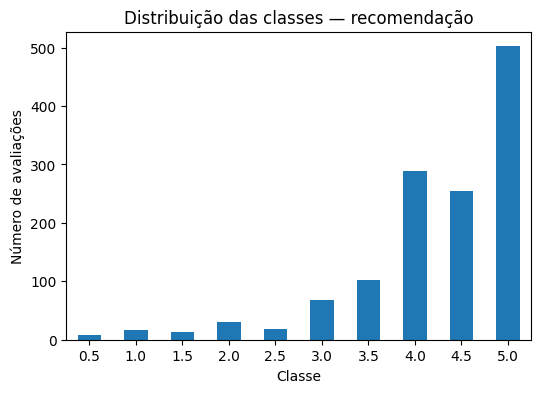

In [ ]:
import matplotlib.pyplot as plt

df["nota_resenha"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribuição das classes — recomendação")
plt.xlabel("Classe")
plt.ylabel("Número de avaliações")
plt.xticks(rotation=0)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 42
X = df_classificacao["resenha_limpa"]
y = df_classificacao["classe_sentimento_referencia"]

stratificar = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=stratificar
)
print("Treino:", len(X_train), "| Teste:", len(X_test))

Treino: 1040 | Teste: 261


In [ ]:
modelo_classificacao = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, min_df=2, max_df=0.95,
        ngram_range=(1, 2), max_features=20000
    )),
    ("classificador", LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
modelo_classificacao.fit(X_train, y_train)
print("Classificador treinado para prever classe derivada da nota do usuário.")

Classificador treinado para prever classe derivada da nota do usuário.


In [ ]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

y_pred = modelo_classificacao.predict(X_test)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro: {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print("\\nRelatório por classe:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Acurácia: 0.701
F1 macro: 0.386
\nRelatório por classe:
              precision    recall  f1-score   support

    Negativo      0.222     0.143     0.174        14
      Neutro      0.162     0.158     0.160        38
    Positivo      0.814     0.837     0.825       209

    accuracy                          0.701       261
   macro avg      0.399     0.379     0.386       261
weighted avg      0.687     0.701     0.694       261



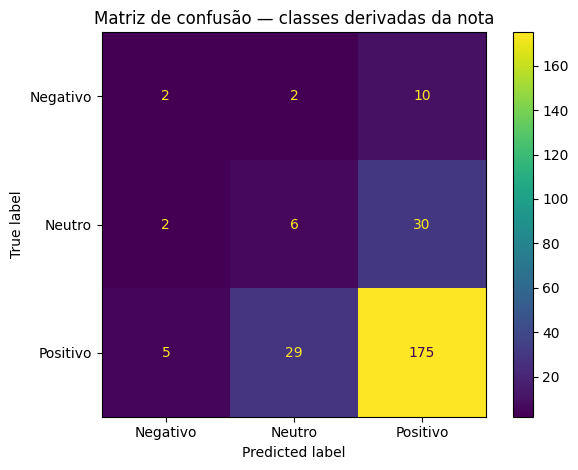

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["Negativo", "Neutro", "Positivo"],
    display_labels=["Negativo", "Neutro", "Positivo"],
    cmap=None, values_format="d"
)
plt.title("Matriz de confusão — classes derivadas da nota")
plt.tight_layout()
plt.show()

In [ ]:
vetorizador = modelo_classificacao.named_steps["tfidf"]
classificador = modelo_classificacao.named_steps["classificador"]
termos = vetorizador.get_feature_names_out()

for classe, coeficientes in zip(classificador.classes_, classificador.coef_):
    top = np.argsort(coeficientes)[-15:][::-1]
    print(f"\\nTermos mais associados à classe {classe}:")
    display(pd.DataFrame({
        "termo": termos[top],
        "coeficiente": coeficientes[top]
    }))

\nTermos mais associados à classe Negativo:


,termo,coeficiente
0,bad,1.693956
1,jonas,1.690737
2,don,1.528524
3,all the,1.445449
4,wuthering,1.402314
5,heights,1.336805
6,why,1.239808
7,wants,1.075839
8,bohemian,1.007378
9,bohemian rhapsody,1.007378


\nTermos mais associados à classe Neutro:


,termo,coeficiente
0,bitch,1.047153
1,said,0.979685
2,rango,0.958762
3,he,0.951595
4,kind of,0.884410
5,great,0.880815
6,ve,0.873029
7,actually,0.823021
8,nosferatu,0.819653
9,kind,0.801492


\nTermos mais associados à classe Positivo:


,termo,coeficiente
0,my,1.122322
1,me,0.798211
2,by,0.686622
3,man,0.685648
4,to the,0.578394
5,as,0.572358
6,her,0.556743
7,war,0.539476
8,would,0.536079
9,in my,0.526923


In [ ]:
novos_textos = [
    "Best war movie I've seen in years.",
    "what if i said pixars best film what then",
    "This movie DESTROYED me.",
    "Probably the funniest movie ever made."
]
previsoes = modelo_classificacao.predict(novos_textos)
probabilidades = modelo_classificacao.predict_proba(novos_textos)
classes = modelo_classificacao.named_steps["classificador"].classes_

resultado_novos = pd.DataFrame({
    "texto": novos_textos,
    "classe_prevista": previsoes
})
for i, classe in enumerate(classes):
    resultado_novos[f"prob_{classe}"] = probabilidades[:, i]

display(resultado_novos)

,texto,classe_prevista,prob_Negativo,prob_Neutro,prob_Positivo
0,Best war movie I've seen in years.,Positivo,0.126680,0.221457,0.651863
1,what if i said pixars best film what then,Positivo,0.282813,0.182893,0.534295
2,This movie DESTROYED me.,Positivo,0.319860,0.125781,0.554359
3,Probably the funniest movie ever made.,Positivo,0.118482,0.210352,0.671166


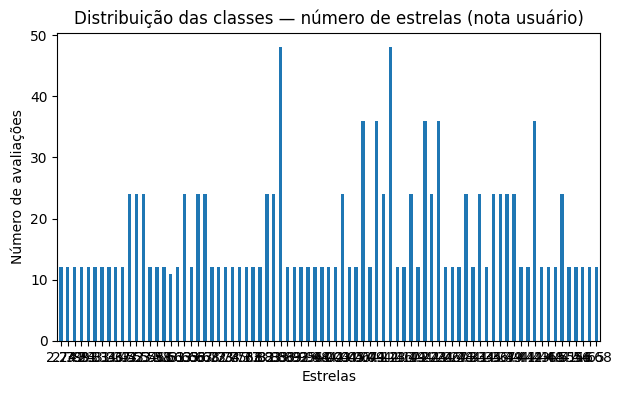

In [ ]:
df["nota_media_letterboxd"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribuição das classes — número de estrelas (nota usuário)")
plt.xlabel("Estrelas")
plt.ylabel("Número de avaliações")
plt.xticks(rotation=0)
plt.show()


In [ ]:
X_multi = df_classificacao["resenha_limpa"]
y_multi = df_classificacao["nota_resenha"].astype(float)

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=RANDOM_STATE
)
print("Treino:", len(X_train_multi), "| Teste:", len(X_test_multi))

Treino: 1040 | Teste: 261


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

modelo_regressao = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, min_df=2, max_df=0.95,
        ngram_range=(1, 2), max_features=20000
    )),
    ("regressor", Ridge(alpha=1.0))
])
modelo_regressao.fit(X_train_multi, y_train_multi)
y_pred_multi = modelo_regressao.predict(X_test_multi)
y_pred_multi = np.clip(y_pred_multi, 0.5, 5.0)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print("=== Métricas de regressão para nota da resenha ===")
print(f"MAE: {mae_multi:.4f}")
print(f"MSE: {mse_multi:.4f}")
print(f"R²: {r2_multi:.4f}")

=== Métricas de regressão para nota da resenha ===
MAE: 0.6837
MSE: 0.8769
R²: 0.0106


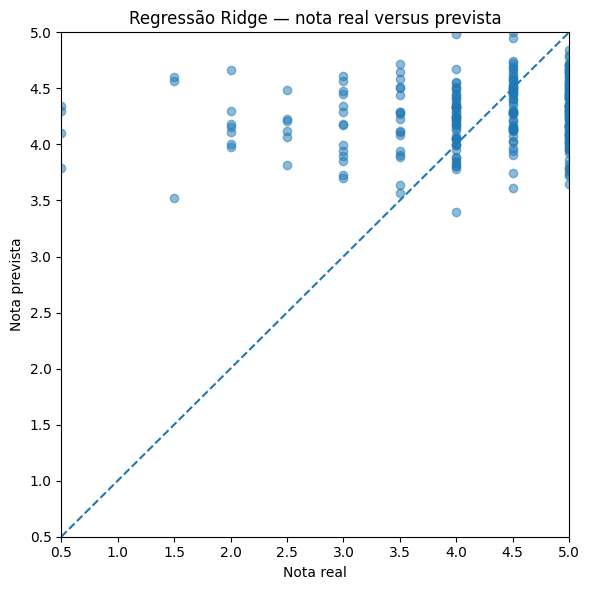

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_multi, y_pred_multi, alpha=0.5)
limites = [0.5, 5.0]
plt.plot(limites, limites, linestyle="--")
plt.xlim(limites); plt.ylim(limites)
plt.xlabel("Nota real")
plt.ylabel("Nota prevista")
plt.title("Regressão Ridge — nota real versus prevista")
plt.tight_layout()
plt.show()

In [ ]:
erros = pd.DataFrame({
    "texto": X_test_multi.to_numpy(),
    "real": np.asarray(y_test_multi),
    "previsto": np.asarray(y_pred_multi)
})
erros["erro_absoluto"] = (erros["real"] - erros["previsto"]).abs()
display(erros.sort_values("erro_absoluto", ascending=False).head(10))

,texto,real,previsto,erro_absoluto
123,bad haircut,0.5,4.341353,3.841353
166,"""You're not a Nazi, Jojo. You're a ten year ol...",0.5,4.300948,3.800948
186,"Move over, Triumph of the Will. We've got a fr...",0.5,4.102601,3.602601
110,the real villain here is whoever approved Mal'...,0.5,3.793700,3.293700
194,What I learned from this movie:,1.5,4.604235,3.104235
109,"""Chad Charming"" is the greatest name for a cha...",1.5,4.568637,3.068637
2,finally a movie that shows us what is on our p...,2.0,4.665921,2.665921
207,the auradon royal family is republican,2.0,4.297830,2.297830
134,Realizing that Emerald Fennell so wildly misre...,2.0,4.178696,2.178696
40,Michael Jackson will return in Avengers: Doomsday,2.0,4.155355,2.155355


In [ ]:
erros["erro"] = erros["previsto"] - erros["real"]
display(erros[["real", "previsto", "erro", "erro_absoluto"]].describe().round(3))

,real,previsto,erro,erro_absoluto
count,261.000,261.000,261.000,261.000
mean,4.251,4.269,0.018,0.684
std,0.943,0.286,0.938,0.641
min,0.500,3.400,-1.351,0.001
25%,4.000,4.082,-0.628,0.271
50%,4.500,4.285,-0.211,0.544
75%,5.000,4.489,0.344,0.900
max,5.000,5.000,3.841,3.841


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
d = df.dropna(subset=["nota_resenha", "resenha_limpa"]).drop_duplicates(["resenha_limpa", "nota_resenha"])
y = d["nota_resenha"].apply(lambda n: "Negativo" if n <= 2 else "Neutro" if n < 4 else "Positivo").to_numpy()
pos = df.index.get_indexer(d.index)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
linhas = []
for nome, X in REPS.items():
    Xs = X[pos]
    for mn, m in {"Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
                  "Random Forest": RandomForestClassifier(300, class_weight="balanced", random_state=42, n_jobs=-1)}.items():
        r = cross_validate(m, Xs, y, cv=cv, scoring=["accuracy", "f1_macro"])
        linhas.append(dict(representacao=nome, modelo=mn, acuracia=r["test_accuracy"].mean(),
                           f1_macro=r["test_f1_macro"].mean(), f1_macro_dp=r["test_f1_macro"].std()))
res_clf = pd.DataFrame(linhas).sort_values("f1_macro", ascending=False)
display(res_clf.round(3))
print(f"Baseline (prever sempre 'Positivo'): acurácia = {(y == 'Positivo').mean():.3f} | n = {len(y)}")
res_clf.to_csv("figuras/resultados_classificacao.csv", index=False)

,representacao,modelo,acuracia,f1_macro,f1_macro_dp
6,BERT,Regressão Logística,0.552,0.393,0.029
0,BoW,Regressão Logística,0.729,0.368,0.031
2,TF-IDF,Regressão Logística,0.753,0.332,0.017
4,Word2Vec,Regressão Logística,0.474,0.319,0.016
1,BoW,Random Forest,0.790,0.304,0.012
3,TF-IDF,Random Forest,0.795,0.302,0.007
5,Word2Vec,Random Forest,0.802,0.297,0.000
7,BERT,Random Forest,0.802,0.297,0.000


Baseline (prever sempre 'Positivo'): acurácia = 0.802 | n = 1301


parse


In [ ]:
%pip -q install spacy pandas networkx matplotlib
!python -m spacy download en_core_web_sm

import spacy
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from spacy import displacy

nlp = spacy.load("en_core_web_sm")
print("spaCy:", spacy.__version__, "| Modelo:", nlp.meta["version"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 95.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy: 3.8.16 | Modelo: 3.8.0


In [ ]:
frases = [
    "The protagonist's performance was simply spectacular and thrilling.",
    "The script for this science fiction film loses its way in the second half.",
    "Hans Zimmer's cinematography and soundtrack save a confusing direction.",
    "I don't understand the critical acclaim for such a predictable thriller.",
    "A horror classic that manages to hold the viewer's attention from beginning to end."
]

frases

["The protagonist's performance was simply spectacular and thrilling.",
 'The script for this science fiction film loses its way in the second half.',
 "Hans Zimmer's cinematography and soundtrack save a confusing direction.",
 "I don't understand the critical acclaim for such a predictable thriller.",
 "A horror classic that manages to hold the viewer's attention from beginning to end."]

In [ ]:
def analisar_dependencias(texto):
    doc = nlp(texto)

    dados = [
        {
            "token": token.text,
            "lema": token.lemma_,
            "classe": token.pos_,
            "dependência": token.dep_,
            "núcleo": token.head.text
        }
        for token in doc
    ]

    return pd.DataFrame(dados)

analisar_dependencias(frases[0])


,token,lema,classe,dependência,núcleo
0,The,the,DET,det,protagonist
1,protagonist,protagonist,NOUN,poss,performance
2,'s,'s,PART,case,protagonist
3,performance,performance,NOUN,nsubj,was
4,was,be,AUX,ROOT,was
5,simply,simply,ADV,advmod,was
6,spectacular,spectacular,ADJ,acomp,was
7,and,and,CCONJ,cc,spectacular
8,thrilling,thrilling,ADJ,conj,spectacular
9,.,.,PUNCT,punct,was


In [ ]:
analisar_dependencias(frases[3])


,token,lema,classe,dependência,núcleo
0,I,I,PRON,nsubj,understand
1,do,do,AUX,aux,understand
2,n't,not,PART,neg,understand
3,understand,understand,VERB,ROOT,understand
4,the,the,DET,det,acclaim
5,critical,critical,ADJ,amod,acclaim
6,acclaim,acclaim,NOUN,dobj,understand
7,for,for,ADP,prep,acclaim
8,such,such,DET,predet,thriller
9,a,a,DET,det,thriller


In [ ]:
for indice in [0, 2]:
    displacy.render(nlp(frases[indice]), style="dep", jupyter=True,
                    options={"compact": True, "distance": 100})


In [ ]:
frases_ner = [
    "You know how there are some movies that are clearly too good to be on Disney but they somehow are anyway?",
    "End of evangelion but for people who go to therapy",
    "lowkey? one of the best Pixar films",
    "heath ledger: *dances down steps with giant leaps*",
    "Minecraft cave noises prepared me for this",
    "summer: i love the smiths."
]

frases_ner


['You know how there are some movies that are clearly too good to be on Disney but they somehow are anyway?',
 'End of evangelion but for people who go to therapy',
 'lowkey? one of the best Pixar films',
 'heath ledger: *dances down steps with giant leaps*',
 'Minecraft cave noises prepared me for this',
 'summer: i love the smiths.']

In [ ]:
def extrair_entidades(texto):
    return pd.DataFrame([
        {"entidade": ent.text, "categoria": ent.label_,
         "início": ent.start_char, "fim": ent.end_char}
        for ent in nlp(texto).ents
    ], columns=["entidade", "categoria", "início", "fim"])

extrair_entidades(frases_ner[1])


,entidade,categoria,início,fim


In [ ]:
N_AMOSTRA_NER = min(300, len(df))
amostra_ner = df[["filme", "resenha_original"]].dropna().head(N_AMOSTRA_NER).copy()

registros_entidades = []
for idx, row in tqdm(amostra_ner.iterrows(), total=len(amostra_ner), desc="NER na amostra"):
    doc = nlp(str(row["resenha_original"])[:3000])
    for ent in doc.ents:
        registros_entidades.append({
            "indice_df": idx,
            "filme": row["filme"],
            "entidade": ent.text,
            "categoria": ent.label_,
            "descricao_categoria": spacy.explain(ent.label_)
        })

df_entidades_base = pd.DataFrame(
    registros_entidades,
    columns=["indice_df", "filme", "entidade", "categoria", "descricao_categoria"]
)
print(f"Resenhas analisadas: {len(amostra_ner)} | Entidades extraídas: {len(df_entidades_base)}")
if not df_entidades_base.empty:
    display(df_entidades_base.head(30))
    display(df_entidades_base["categoria"].value_counts().rename("quantidade").to_frame())
else:
    print("Nenhuma entidade reconhecida na amostra.")

NER na amostra:   0%|          | 0/300 [00:00<?, ?it/s]

Resenhas analisadas: 300 | Entidades extraídas: 432


,indice_df,filme,entidade,categoria,descricao_categoria
0,0,10 Things I Hate About You,joseph gordon-levitt,PERSON,"People, including fictional"
1,1,10 Things I Hate About You,kat stratford,PERSON,"People, including fictional"
2,1,10 Things I Hate About You,20 year old,DATE,Absolute or relative dates or periods
3,3,10 Things I Hate About You,joseph gordon-levitt,PERSON,"People, including fictional"
4,9,10 Things I Hate About You,joey,PERSON,"People, including fictional"
5,10,10 Things I Hate About You,thai,NORP,Nationalities or religious or political groups
6,12,1917,1917,DATE,Absolute or relative dates or periods
7,13,1917,ListProgress,ORG,"Companies, agencies, institutions, etc."
8,13,1917,57%,PERCENT,"Percentage, including ""%"""
9,15,1917,andrew scott,PERSON,"People, including fictional"


,quantidade
categoria,
ORG,173
PERSON,122
CARDINAL,32
DATE,27
GPE,27
ORDINAL,11
PRODUCT,9
TIME,9
NORP,7


In [ ]:
nlp.get_pipe("ner").labels


('CARDINAL',
 'DATE',
 'EVENT',
 'FAC',
 'GPE',
 'LANGUAGE',
 'LAW',
 'LOC',
 'MONEY',
 'NORP',
 'ORDINAL',
 'ORG',
 'PERCENT',
 'PERSON',
 'PRODUCT',
 'QUANTITY',
 'TIME',
 'WORK_OF_ART')

In [ ]:
displacy.render(nlp(frases_ner[0]), style="ent", jupyter=True)


In [ ]:
texto = """
Mila Kunis going down on Natalie Portman IS modern cinema.
So strange that life goes on after finishing a film like Call Me By Your Name.
Do not ever, EVER, travel anywhere with Matt Damon
"""

extrair_entidades(texto)

# para extrair nomes de pessoas ele é eficiente, porém, os nomes precisam estar com
# a primeira inicial maiscula. O EVER (palavra toda em maisculo)
# que considerou como ORG é referente a uma
# associação europeia, quando a palavra é "ever" ele não considera
# a categoria correta do filme Call Me By Your Name seria WORK_OF_ART mas
# em relação a isso pode ocorrer erros também

,entidade,categoria,início,fim
0,Mila Kunis,PERSON,1,11
1,Natalie Portman,PERSON,26,41
2,Call Me By Your Name,ORG,117,137
3,EVER,ORG,152,156
4,Matt Damon\n,PERSON,179,190


In [ ]:
frases_relacoes = [
    "Finally they cast Michael A. Jordan in something.",
    "Everyone involved in this deserves recognition but if anyone should get that ‘best actor’ award this year, it’s Riz. And it isn’t even close!."
]

frases_relacoes


['Finally they cast Michael A. Jordan in something.',
 'Everyone involved in this deserves recognition but if anyone should get that ‘best actor’ award this year, it’s Riz. And it isn’t even close!.']

In [ ]:
doc = nlp(frases_relacoes[1])
pd.DataFrame([
    {"função": token.dep_, "núcleo": token.text,
     "sintagma": " ".join(t.text for t in token.subtree)}
    for token in doc if token.dep_ in {"nsubj", "nsubjpass", "dobj"}
])

,função,núcleo,sintagma
0,nsubj,Everyone,Everyone involved in this
1,dobj,recognition,recognition
2,nsubj,anyone,anyone
3,dobj,award,that ‘ best actor ’ award
4,nsubj,it,it
5,nsubj,it,it


In [ ]:
def obter_sintagma(token):
    tokens = list(token.subtree)

    inicio = min(t.i for t in tokens)
    fim = max(t.i for t in tokens) + 1

    return token.doc[inicio:fim].text


def extrair_relacao_svo(texto):
    doc = nlp(texto)

    for verbo in doc:
        if verbo.pos_ == "VERB":
            sujeitos = [t for t in verbo.children if t.dep_ in {"nsubj", "nsubjpass"}]
            objetos = [t for t in verbo.children if t.dep_ in {"dobj", "dative"}]

            for sujeito in sujeitos:
                for objeto in objetos:
                    return {
                        "sujeito": obter_sintagma(sujeito),
                        "relação": verbo.lemma_,
                        "objeto": obter_sintagma(objeto)
                    }

    return None

extrair_relacao_svo(frases_relacoes[0])

{'sujeito': 'they', 'relação': 'cast', 'objeto': 'Michael A. Jordan'}

In [ ]:
pd.DataFrame([
    {"frase": frase, "tripla SVO": extrair_relacao_svo(frase)}
    for frase in frases_relacoes
])


,frase,tripla SVO
0,Finally they cast Michael A. Jordan in something.,"{'sujeito': 'they', 'relação': 'cast', 'objeto..."
1,Everyone involved in this deserves recognition...,"{'sujeito': 'Everyone involved in this', 'rela..."


In [ ]:
analisar_dependencias(frases_relacoes[0])


,token,lema,classe,dependência,núcleo
0,Finally,finally,ADV,advmod,cast
1,they,they,PRON,nsubj,cast
2,cast,cast,VERB,ROOT,cast
3,Michael,Michael,PROPN,compound,Jordan
4,A.,A.,PROPN,compound,Jordan
5,Jordan,Jordan,PROPN,dobj,cast
6,in,in,ADP,prep,cast
7,something,something,PRON,pobj,in
8,.,.,PUNCT,punct,cast


In [ ]:
def obter_argumento(token):
    entidade = next((ent for ent in token.doc.ents
                     if ent.start <= token.i < ent.end), None)
    if entidade is not None:
        return entidade.text
    tokens = sorted((t for t in token.subtree if not t.is_punct),
                    key=lambda t: t.i)
    while tokens and tokens[0].dep_ in {"det", "case"}:
        tokens.pop(0)
    return " ".join(t.text for t in tokens)


def normalizar_preposicao(token):
    mapa = {
        **dict.fromkeys(["onto", "upon"], "on"),
        **dict.fromkeys(["within", "inside"], "in"),
        **dict.fromkeys(["unto"], "to"),
        **dict.fromkeys(["towards"], "toward"),
        **dict.fromkeys(["amongst"], "among"),
        **dict.fromkeys(["amidst"], "amid"),
        **dict.fromkeys(["thru"], "through"),
        **dict.fromkeys(["til", "till"], "until"),
        **dict.fromkeys(["w/"], "with"),
    }
    return mapa.get(token.text.lower(), token.lemma_.lower())

In [ ]:
import re

PRONOMES_PERMITIDOS = {"i", "we", "they"}

def _argumento_valido(token):
    return not (token.pos_ == "PRON" and token.text.lower() not in PRONOMES_PERMITIDOS)

def sujeitos_do_verbo(verbo):
    atual = verbo
    for _ in range(3):
        suj = [t for t in atual.children if t.dep_ in {"nsubj", "nsubjpass"}]
        if suj:
            return suj
        if atual.dep_ in {"xcomp", "conj", "advcl"} and atual.head is not atual:
            atual = atual.head
        else:
            break
    return []

def extrair_relacoes_doc(doc, normalizar=True):
    argumento = obter_argumento if normalizar else obter_sintagma
    saida = []
    for verbo in doc:
        if verbo.pos_ != "VERB":
            continue
        sujeitos = sujeitos_do_verbo(verbo)
        if not sujeitos:
            continue
        negado = any(t.dep_ == "neg" for t in verbo.children)
        passiva = any(t.dep_ in {"nsubjpass", "auxpass"} for t in verbo.children)
        base = ("not_" if negado else "") + ("be_" if passiva else "") + verbo.lemma_.lower()

        complementos = []                                   # (token, relação)
        for filho in verbo.children:
            if filho.dep_ in {"dobj", "dative"}:
                complementos.append((filho, base))
            elif filho.dep_ in {"prep", "agent"}:
                for obj in filho.children:
                    if obj.dep_ == "pobj":
                        complementos.append((obj, f"{base}_{normalizar_preposicao(filho)}"))

        for suj in sujeitos:
            for comp, relacao in complementos:
                if _argumento_valido(suj) and _argumento_valido(comp):
                    saida.append({"sujeito": argumento(suj), "relação": relacao,
                                  "objeto": argumento(comp)})
    return pd.DataFrame(saida, columns=["sujeito", "relação", "objeto"])


def extrair_relacoes(texto, normalizar=True):
    return extrair_relacoes_doc(nlp(re.sub(r"\s+", " ", texto).strip()), normalizar)


extrair_relacoes(frases_relacoes[0])

,sujeito,relação,objeto
0,they,cast,Michael A. Jordan


In [ ]:
N_AMOSTRA_RELACOES = min(200, len(df))
amostra_relacoes = df[["filme", "resenha_original"]].dropna().head(N_AMOSTRA_RELACOES)

resultados_relacoes_base = []
for idx, row in tqdm(amostra_relacoes.iterrows(), total=len(amostra_relacoes),
                     desc="Extração de relações na amostra"):
    texto = str(row["resenha_original"])[:2500]
    relacoes = extrair_relacoes(texto)
    if not relacoes.empty:
        relacoes["indice_df"] = idx
        relacoes["filme_resenhado"] = row["filme"]
        relacoes["texto_origem"] = texto
        resultados_relacoes_base.append(relacoes)

df_relacoes_base = (
    pd.concat(resultados_relacoes_base, ignore_index=True)
    if resultados_relacoes_base
    else pd.DataFrame(columns=[
        "sujeito", "relação", "objeto", "indice_df", "filme_resenhado", "texto_origem"
    ])
)
print(f"Resenhas analisadas: {len(amostra_relacoes)} | Relações extraídas: {len(df_relacoes_base)}")
display(df_relacoes_base.head(30))

Extração de relações na amostra:   0%|          | 0/200 [00:00<?, ?it/s]

Resenhas analisadas: 200 | Relações extraídas: 112


,sujeito,relação,objeto,indice_df,filme_resenhado,texto_origem
0,i too,be_disgust_by,men,1,10 Things I Hate About You,kat stratford is the most relatable character ...
1,i too,be_disgust_except,20 year old heath ledger,1,10 Things I Hate About You,kat stratford is the most relatable character ...
2,I,hate,way this film romanticizes the hard to get gir...,5,10 Things I Hate About You,I hate the way this film romanticizes the hard...
3,film,romanticize,hard,5,10 Things I Hate About You,I hate the way this film romanticizes the hard...
4,film,get,girl trope,5,10 Things I Hate About You,I hate the way this film romanticizes the hard...
5,heath ledger with his hair,cover_in,paint,7,10 Things I Hate About You,"heath ledger with his hair tied up, covered in..."
6,heath ledger with his hair,look_like,human embodiment of sunshine,7,10 Things I Hate About You,"heath ledger with his hair tied up, covered in..."
7,boys,beat,shit,9,10 Things I Hate About You,the scene where bianca finally realises boys a...
8,my dad,whisper,hot priest,15,1917,my cinematic experience was completed when my ...
9,especially Écoust at night,be_light_by,fire and flares,19,1917,What Deakins was able to pull off here is real...


In [ ]:
frases_relacoes = [
    "I like to imagine that the ghost of Johnny Cash haunts James Mangold.",
    "Just found out Awkwafina was originally cast as the daughter and now I’m even more thankful to be in the universe where that didn’t happen.",
    "I can't believe they made a remake of Walk Hard but left out all the jokes.",
    "These oners must’ve been very demanding on MacKay and Chapman and yet they gave really natural performances.",
    "It used to be that every white male wanted to write the next great American novel and now it’s every white male filmmaker wants to make the next great “provocative” movie, and it’s tiring.",
]

comparacao = pd.concat([
    extrair_relacoes(frase, normalizar=opcao).assign(
        versão="normalizada" if opcao else "bruta", frase=frase[:60] + "…")
    for opcao in [False, True] for frase in frases_relacoes
], ignore_index=True)
relacoes_df = comparacao.loc[comparacao["versão"] == "normalizada",
                             ["sujeito", "relação", "objeto"]].copy()
comparacao

,sujeito,relação,objeto,versão,frase
0,I,imagine,that the ghost of Johnny Cash haunts James Man...,bruta,I like to imagine that the ghost of Johnny Cas...
1,Awkwafina,be_cast_as,the daughter,bruta,Just found out Awkwafina was originally cast a...
2,they,make,a remake of Walk Hard,bruta,I can't believe they made a remake of Walk Har...
3,I,leave,all the jokes,bruta,I can't believe they made a remake of Walk Har...
4,they,give,really natural performances,bruta,These oners must’ve been very demanding on Mac...
5,every white male,write,the next great American novel,bruta,It used to be that every white male wanted to ...
6,every white male filmmaker,make,the next great “provocative” movie,bruta,It used to be that every white male wanted to ...
7,I,imagine,that the ghost of Johnny Cash haunts James Man...,normalizada,I like to imagine that the ghost of Johnny Cas...
8,Awkwafina,be_cast_as,daughter,normalizada,Just found out Awkwafina was originally cast a...
9,they,make,remake of Walk Hard,normalizada,I can't believe they made a remake of Walk Har...


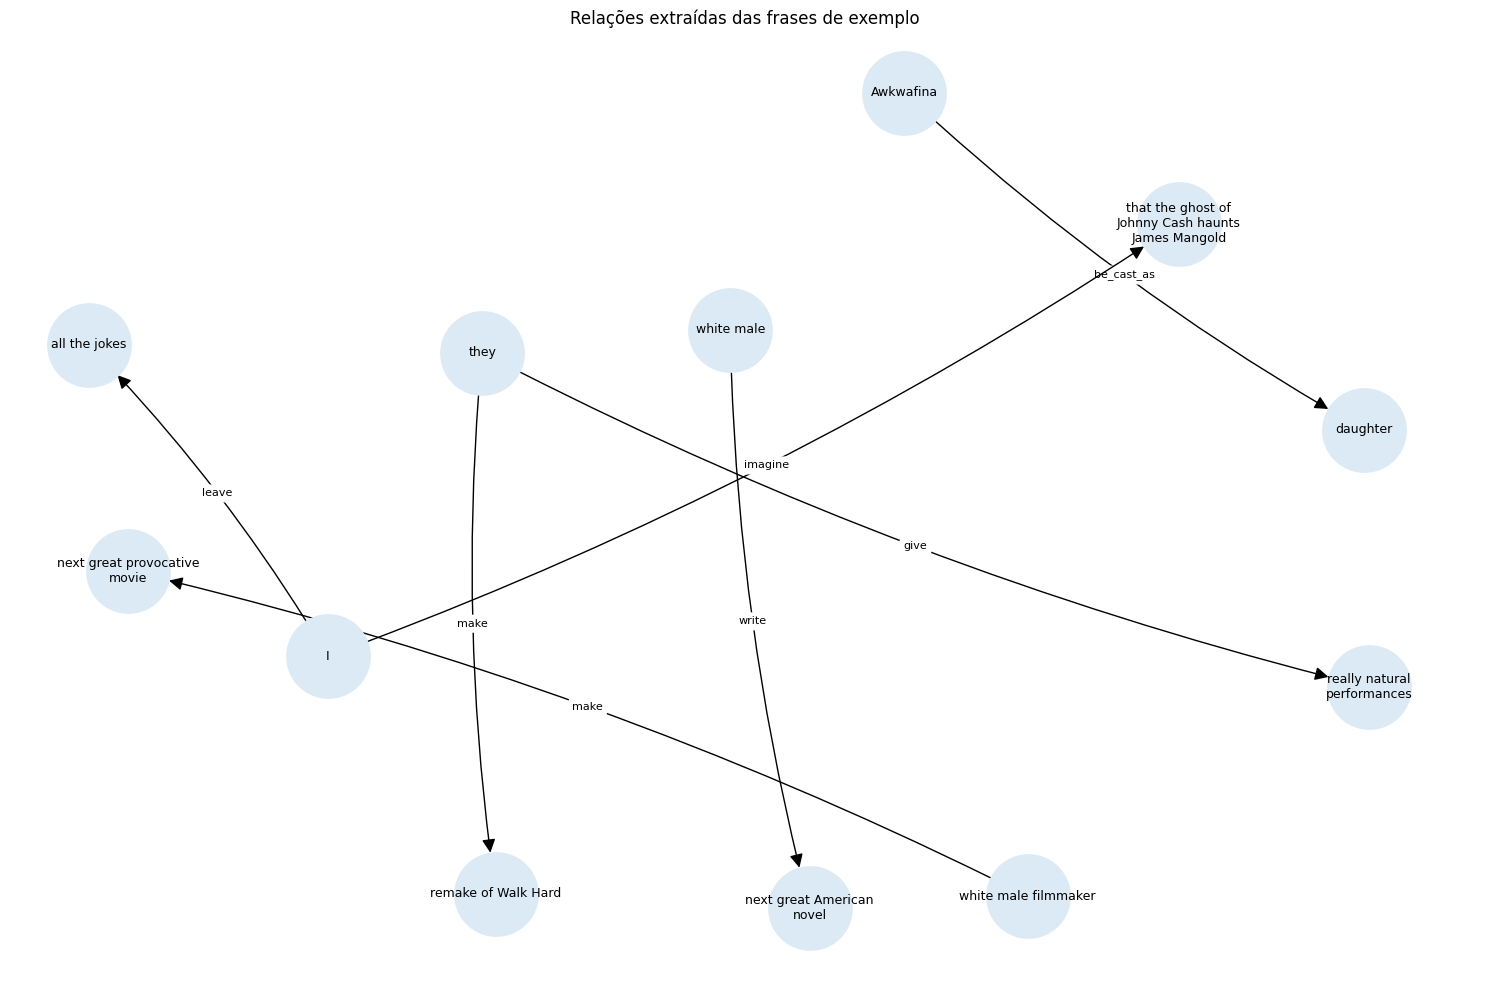

Nós: 12 | Pares direcionados: 7


In [ ]:
import textwrap


def desenhar_grafo(tabela, titulo):
    grafo = nx.DiGraph()
    for (origem, destino), grupo in tabela.groupby(["sujeito", "objeto"], sort=True):
        grafo.add_edge(origem, destino,
                       relação=", ".join(sorted(set(grupo["relação"]))))
    fig, ax = plt.subplots(figsize=(15, 10))
    pos = nx.spring_layout(grafo, seed=42, k=1.8)
    nx.draw_networkx_nodes(grafo, pos, node_size=3600, node_color="#dceaf5", ax=ax)
    nomes = {n: textwrap.fill(n, width=22) for n in grafo.nodes}
    nx.draw_networkx_labels(grafo, pos, labels=nomes, font_size=9, ax=ax)
    for origem, destino, dados in grafo.edges(data=True):
        curva = 0.25 if grafo.has_edge(destino, origem) else 0.06
        nx.draw_networkx_edges(grafo, pos, edgelist=[(origem, destino)],
                               arrows=True, arrowsize=20, node_size=3600,
                               connectionstyle=f"arc3,rad={curva}", ax=ax)
        nx.draw_networkx_edge_labels(
            grafo, pos, edge_labels={(origem, destino):
                textwrap.fill(dados["relação"], width=24)},
            font_size=8, rotate=False, node_size=3600,
            connectionstyle=f"arc3,rad={curva}", ax=ax)
    ax.set_title(titulo)
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Nós: {grafo.number_of_nodes()} | Pares direcionados: {grafo.number_of_edges()}")
    return grafo

G_exemplos = desenhar_grafo(relacoes_df, "Relações extraídas das frases de exemplo")


In [ ]:
texto_longo = """
oh. what do you do when one day you wake up and look at your life and realize this
was never the life you were supposed to have? and you realize that the man who loves
you isn't someone you can respect, and the one man you respect isn't someone you can
forgive? (do you choose your home or your mirror?) worse, how do you confess that you'd
trade your husband and the daughter you made together in a heartbeat for the unbroken knee
that could've made you the greatest in the world?
"""


In [ ]:
doc_longo = nlp(texto_longo.strip())
sentencas = [sent.text.strip() for sent in doc_longo.sents]
pd.DataFrame([
    {"sentença": i, "texto": sent.text.strip(),
     "entidades": [(ent.text, ent.label_) for ent in sent.ents]}
    for i, sent in enumerate(doc_longo.sents, start=1)
])


,sentença,texto,entidades
0,1,oh.,[]
1,2,what do you do when one day you wake up and lo...,"[(one day, DATE)]"
2,3,and you realize that the man who loves\nyou is...,"[(one, CARDINAL)]"
3,4,(do you choose your home or your mirror?),[]
4,5,"worse, how do you confess that you'd\ntrade yo...",[]


In [ ]:
resultados = [
    extrair_relacoes(sentenca).assign(sentença=i, texto=sentenca)
    for i, sentenca in enumerate(sentencas, start=1)
]
relacoes_texto_df = (pd.concat(resultados, ignore_index=True) if resultados
                    else pd.DataFrame(columns=["sujeito", "relação", "objeto",
                                               "sentença", "texto"]))
relacoes_texto_df[["sentença", "sujeito", "relação", "objeto", "texto"]]


,sentença,sujeito,relação,objeto,texto


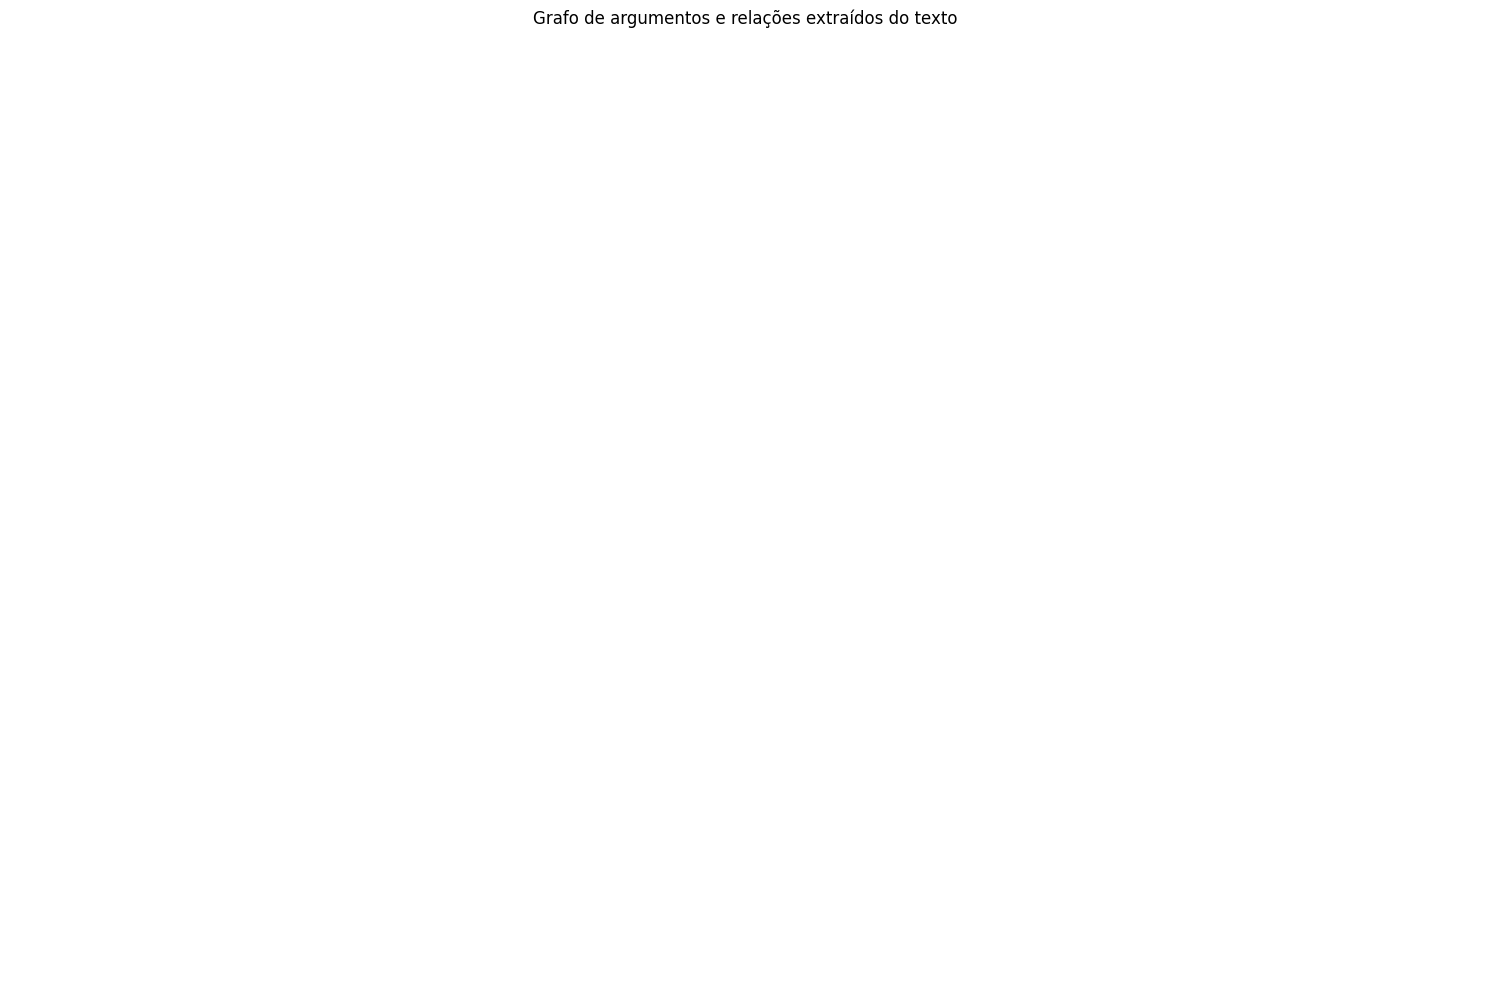

Nós: 0 | Pares direcionados: 0


In [ ]:
G_texto = desenhar_grafo(relacoes_texto_df, "Grafo de argumentos e relações extraídos do texto")


In [ ]:
!pip install -q transformers torch

In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from tqdm.auto import tqdm

device_sentimento = 0 if torch.cuda.is_available() else -1
analisador = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=device_sentimento
)

textos = df["resenha_original"].fillna("").astype(str).tolist()
indices_validos = [i for i, texto in enumerate(textos) if texto.strip()]
textos_validos = [textos[i][:1500] for i in indices_validos]

resultados_validos = []
for inicio in tqdm(range(0, len(textos_validos), 16), desc="Análise de sentimento"):
    lote = textos_validos[inicio:inicio + 16]
    resultados_validos.extend(
        analisador(lote, truncation=True, max_length=512)
    )

df["sentimento_nota"] = np.nan
df["sentimento_confianca"] = np.nan
df["sentimento"] = pd.NA

for indice, resultado in zip(indices_validos, resultados_validos):
    nota = int(resultado["label"].split()[0])
    df.at[df.index[indice], "sentimento_nota"] = nota
    df.at[df.index[indice], "sentimento_confianca"] = float(resultado["score"])
    df.at[df.index[indice], "sentimento"] = (
        "Negativo" if nota <= 2 else "Neutro" if nota == 3 else "Positivo"
    )

display(df[[
    "filme", "resenha_original", "nota_resenha",
    "sentimento_nota", "sentimento_confianca", "sentimento"
]].head(10))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Análise de sentimento:   0%|          | 0/87 [00:00<?, ?it/s]

,filme,resenha_original,nota_resenha,sentimento_nota,sentimento_confianca,sentimento
0,10 Things I Hate About You,the moral of the story is that all men are evi...,5.0,1.0,0.269418,Negativo
1,10 Things I Hate About You,kat stratford is the most relatable character ...,5.0,1.0,0.321498,Negativo
2,10 Things I Hate About You,me: i hate cliches,5.0,1.0,0.577521,Negativo
3,10 Things I Hate About You,funny how shakespeare’s been real quiet since ...,5.0,5.0,0.485102,Positivo
4,10 Things I Hate About You,heath ledger: *dances down steps with giant le...,3.5,4.0,0.322166,Positivo
5,10 Things I Hate About You,I hate the way this film romanticizes the hard...,4.0,2.0,0.406459,Negativo
6,10 Things I Hate About You,"dear men, what’s stopping you from being like ...",5.0,5.0,0.325692,Positivo
7,10 Things I Hate About You,"heath ledger with his hair tied up, covered in...",5.0,2.0,0.349031,Negativo
8,10 Things I Hate About You,this is the best high school film bc it includ...,4.0,5.0,0.781683,Positivo
9,10 Things I Hate About You,the scene where bianca finally realises boys a...,5.0,3.0,0.260125,Neutro


Quantidade de resenhas por sentimento:
sentimento
Negativo    552
Neutro      165
Positivo    665
Name: count, dtype: int64


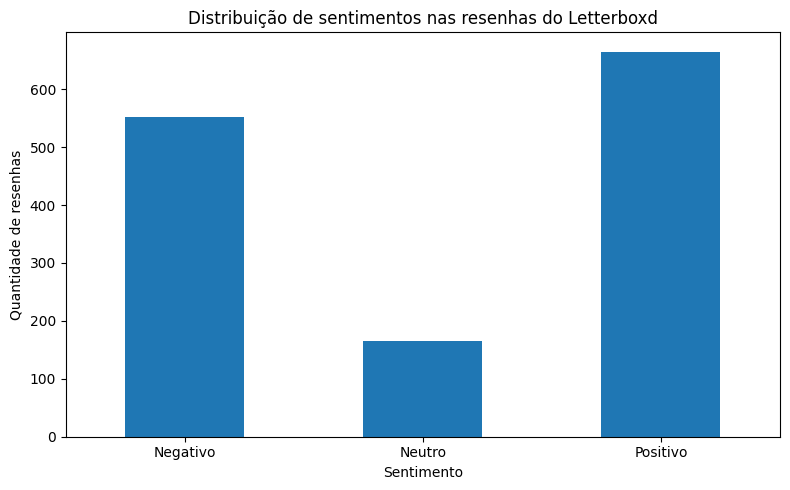

In [ ]:
import matplotlib.pyplot as plt

ordem = ["Negativo", "Neutro", "Positivo"]

contagem = (
    df["sentimento"]
    .value_counts()
    .reindex(ordem, fill_value=0)
)

print("Quantidade de resenhas por sentimento:")
print(contagem)

contagem.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Distribuição de sentimentos nas resenhas do Letterboxd")
plt.xlabel("Sentimento")
plt.ylabel("Quantidade de resenhas")
plt.tight_layout()
plt.show()

In [ ]:
df["nota_resenha"] = pd.to_numeric(df["nota_resenha"], errors="coerce")
df["sentimento_nota"] = pd.to_numeric(df["sentimento_nota"], errors="coerce")

resumo_filmes = (
    df.groupby("filme")
    .agg(
        total_resenhas=("sentimento", "count"),
        nota_media_usuarios=("nota_resenha", "mean"),
        nota_media_modelo=("sentimento_nota", "mean"),
        percentual_positivo=(
            "sentimento",
            lambda s: (s == "Positivo").mean() * 100
        ),
        percentual_negativo=(
            "sentimento",
            lambda s: (s == "Negativo").mean() * 100
        )
    )
    .round(2)
    .sort_values("percentual_positivo", ascending=False)
)

resumo_filmes.head(15)

,total_resenhas,nota_media_usuarios,nota_media_modelo,percentual_positivo,percentual_negativo
filme,,,,,
Bebé Lilly - O meu DVD,1,5.00,5.00,100.00,0.00
Train Dreams,12,4.27,4.33,83.33,8.33
The Best of the Andy Williams: Christmas Shows,5,3.33,3.80,80.00,20.00
A Charlie Brown Christmas,12,4.90,3.83,75.00,25.00
Jackass Forever,12,4.33,4.00,75.00,16.67
Sinners,12,4.38,4.00,75.00,25.00
Paris Is Burning,12,4.71,4.08,75.00,25.00
The Odyssey,12,4.12,4.17,75.00,16.67
"The Good, the Bad and the Ugly",12,4.64,4.33,75.00,8.33
